# M09b · Moindres carrés et régularisation — solutions (notebook exécuté)

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/cemah2/workbookMaths/blob/main/chapitres/m09b_moindres_carres/05_solutions.ipynb)

Les réponses des exercices, exécutées. Les démarches détaillées (le *pourquoi*, les erreurs fréquentes, les variantes) sont dans `05_solutions.md`. Les cellules marquées `answer` enregistrent les réponses vérifiées par `wbm.check` (`tools/build_answers.py`).

| Partie | ID | Titre | Type | ★ | ⏱️ |
|---|---|---|---|---|---|
| 0 | M09b.1 à M09b.12, M09b.20, M09b.21 | Les exercices papier (vérification) | ✏️ 🔗 | | |
| A | M09b.26 | Équations normales et résolution, avec ou sans ridge · `normal_equations, solve_least_squares` | 🔨 | ★ | 25 |
|  | M09b.27 | La matrice chapeau et les trois sommes de carrés · `hat_matrix, residual_decomposition` | 🔨 | ★ | 20 |
|  | M09b.28 | Compter les monômes, et la loss de Huber · `count_monomials, huber_loss` | 🔨 | ★ | 15 |
|  | M09b.29 | `np.linalg.lstsq` et scikit-learn contre tes équations normales | 📦 | ★ | 15 |
| B | M09b.30 | Prédire : le R² d'entraînement quand on ajoute une feature de pur bruit | 🔮 | ★ | 10 |
|  | M09b.31 | Simuler l'estimateur rétréci c·x̄ : le c qui minimise l'erreur quadratique | 🔬 | ★★ | 20 |
|  | M09b.32 | Le conditionnement de XᵀX avec des puissances non standardisées | 🔬 | ★★ | 20 |
|  | M09b.33 | Les lignes de niveau de la loss des moindres carrés en dimension 2, et son gradient | 🎨 | ★ | 20 |
| C | M09b.34 | Chasse à l'erreur : XXᵀ au lieu de XᵀX, un gradient de mauvais signe, un R² sans centrer | 🐛 | ★ | 15 |
|  | M09b.35 | Vérifier un gradient matriciel avec SymPy et par différences finies | 🛠️ | ★ | 15 |
|  | M09b.36 | Défi : approcher une fonction par un polynôme de degré au plus 5, avec une erreur maximale sous 1e−3 | 🏆 | ★★★ | 25 |

In [1]:
# ⚙️ SETUP: run this cell first (on Colab or on your computer)
FAST_MODE = True  # True = quick version (a few seconds per cell); False = bigger experiments
SEED = 42

import os
import subprocess
import sys
from pathlib import Path

REPO_URL = "https://github.com/cemah2/workbookMaths.git"
DRIVE_DIR = Path("/content/drive/MyDrive/workbookMaths")

try:
    import google.colab  # noqa: F401  (this module only exists on Colab)
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

if IN_COLAB:
    from google.colab import drive

    drive.mount("/content/drive")
    subprocess.run(["git", "config", "--global", "--add", "safe.directory", str(DRIVE_DIR)])
    if not (DRIVE_DIR / ".git").exists():
        subprocess.run(["git", "clone", REPO_URL, str(DRIVE_DIR)], check=True)
    else:
        # Get the new chapters. Your own work only lives in mon_travail/, which Claude never
        # touches, so "rebase + autostash" keeps it safe (even with local commits).
        identity = subprocess.run(["git", "-C", str(DRIVE_DIR), "config", "user.email"],
                                  capture_output=True).returncode == 0
        who = [] if identity else ["-c", "user.name=Workbook", "-c", "user.email=workbook@localhost"]
        pull = subprocess.run(["git", *who, "-C", str(DRIVE_DIR), "pull", "--rebase", "--autostash"],
                              capture_output=True, text=True)
        conflicts = subprocess.run(["git", "-C", str(DRIVE_DIR), "diff", "--name-only", "--diff-filter=U"],
                                   capture_output=True, text=True).stdout.split()
        if conflicts:  # a file changed outside mon_travail/ AND by Claude: git leaves conflict markers in it
            print("⚠️ Tes modifications de " + ", ".join(conflicts) + " (hors de mon_travail/) entrent en conflit "
                  "avec la nouvelle version ; elles sont gardées dans `git stash`. Pour reprendre la version du "
                  "dépôt : git restore --source=HEAD --staged --worktree <fichier> (00_setup/COLAB.md, « Problèmes "
                  "fréquents »).")
        elif pull.returncode != 0:
            print("⚠️ git pull a échoué (voir 00_setup/COLAB.md, « Problèmes fréquents ») :\n" + pull.stderr)
    ROOT = DRIVE_DIR
else:
    ROOT = Path(os.environ.get("WBM_ROOT", Path.cwd())).resolve()
    while not (ROOT / "src" / "wbm").exists() and ROOT != ROOT.parent:
        ROOT = ROOT.parent
    if not (ROOT / "src" / "wbm").exists():
        raise FileNotFoundError("Dépôt introuvable : ouvre ce notebook depuis le dossier de workbookMaths.")

os.environ["WBM_ROOT"] = str(ROOT)
if str(ROOT / "src") not in sys.path:
    sys.path.insert(0, str(ROOT / "src"))

import wbm  # noqa: E402

cfg = wbm.setup(seed=SEED, fast=FAST_MODE)
FAST_MODE = cfg.fast
mymath = wbm.load_mymath("ref")  # reference implementation

🧪 workbookMaths : environnement
   Plateforme : Local (Linux x86_64, 2 CPU)
   Python 3.13.18 | numpy 2.1.3 | scipy 1.16.3 | sympy 1.14.0 | matplotlib 3.10.0 | pandas 2.2.3 | scikit-learn 1.6.1
   Graine : 42 | FAST_MODE : True


## Objectifs et rappel express

- Vérifier tes calculs papier (partie 0) : losses et $R^2$, sommes de carrés, gradients, équations normales, colonne de 1, matrice chapeau, monômes, ridge et MAP, pénalités L1 et L2, log-vraisemblance, estimateur rétréci, un pas de descente de gradient, la standardisation avant ridge.
- Écrire les six fonctions de `mymath/linreg.py` et les tester, puis comparer avec `lstsq` et scikit-learn.
- Prédire l'effet de features de bruit, simuler un estimateur rétréci, mesurer un conditionnement, tracer une loss, chasser des erreurs, vérifier un gradient, approcher une fonction.

**Rappel express.** $\mathrm{MSE} = \frac{1}{n}\lVert \mathbf{r} \rVert^2$, $R^2 = 1 - \frac{\mathrm{SCR}}{\mathrm{SCT}}$ ; $\nabla(\mathbf{a}^\top\mathbf{w}) = \mathbf{a}$, $\nabla(\mathbf{w}^\top\mathbf{A}\mathbf{w}) = (\mathbf{A} + \mathbf{A}^\top)\mathbf{w}$, $\nabla\lVert \mathbf{y} - \mathbf{X}\mathbf{w} \rVert^2 = -2\mathbf{X}^\top(\mathbf{y} - \mathbf{X}\mathbf{w})$ ; $\mathbf{X}^\top\mathbf{X}\,\mathbf{w} = \mathbf{X}^\top\mathbf{y}$ ; $\mathbf{H} = \mathbf{X}(\mathbf{X}^\top\mathbf{X})^{-1}\mathbf{X}^\top$ ; $\binom{p + d}{d}$ monômes ; ridge : $(\mathbf{X}^\top\mathbf{X} + \lambda\mathbf{I})\mathbf{w} = \mathbf{X}^\top\mathbf{y}$, $\lambda = \sigma^2/\tau^2$ ; erreur = biais² + variance + bruit.

## Partie 0 · Vérifier tes exercices papier (✏️ M09b.1 à M09b.12, 🔗 M09b.20 et M09b.21)

Fais d'abord les exercices de `02_exercices.md` **sur papier**, dans ta copie de `06_mes_reponses.md`. Reporte ensuite chaque réponse ici : **la valeur** que tu as trouvée, sous la forme indiquée en commentaire, jamais le calcul qui y mène :
- un entier, ou un nombre avec un point décimal, `-1.25`, arrondi comme le demande la question ;
- une fraction irréductible entre guillemets, `"4/11"` ;
- une liste `[2, -1, 0]` pour un vecteur ou une forme, une liste de lignes `[[1, 0], [-2, 3]]` pour une matrice, `True` / `False`, ou des lettres entre guillemets, `"AC"`.

Les réponses pas encore remplies affichent ⏳.

In [2]:
# Part 0: the answers are computed exactly from the statements
import math

import numpy as np

Y1 = np.array([12, 7, 9, 15], dtype=float)                                                           # M09b.1
R1 = Y1 - np.array([10, 8, 9.5, 11])


def huber_mean(r, delta):
    """The mean Huber loss of the residuals r."""
    a = np.abs(r)
    return float(np.mean(np.where(a <= delta, r ** 2 / 2, delta * (a - delta / 2))))


X20 = np.array([[1, 2, 1], [1, 0, -1], [1, 1, 3], [1, -1, 0]], dtype=float)                       # M09b.20
Y20, W20 = np.array([3, 0, 1, 1], dtype=float), np.array([0.5, 1, -1])
R20 = Y20 - X20 @ W20
G20 = -2 / 4 * X20.T @ R20

**Ex M09b.1 — MSE, RMSE, MAE et loss de Huber de quatre résidus**

In [3]:
wbm.record("M09b.1a", R1.tolist(), decimals=1, mistakes={"un résidu est y − ŷ : la valeur réelle moins la prédiction": (-R1).tolist()})
wbm.record("M09b.1b", float(np.mean(R1 ** 2)), decimals=4, mistakes={"la MSE est une moyenne : divise la somme des carrés par n": float(np.sum(R1 ** 2)), "c'est la RMSE ; la MSE est la moyenne des carrés, sans racine": float(np.sqrt(np.mean(R1 ** 2)))})
wbm.record("M09b.1c", float(np.mean(np.abs(R1))), decimals=3, mistakes={"la MAE est la moyenne des valeurs absolues : un résidu négatif compte en positif": float(np.mean(R1))})
wbm.record("M09b.1d", huber_mean(R1, 1.0), decimals=5, mistakes={"au-dessus de δ, la loss vaut δ(|r| − δ/2), pas |r|": float(np.mean(np.where(np.abs(R1) <= 1, R1 ** 2 / 2, np.abs(R1)))), "sous δ, la loss vaut r²/2 : le facteur 1/2 compte": float(np.mean(np.where(np.abs(R1) <= 1, R1 ** 2, np.abs(R1) - 0.5)))})
wbm.record("M09b.1e", huber_mean(R1, 5.0), decimals=5, mistakes={"sous δ, la loss vaut r²/2, pas r²": float(np.mean(R1 ** 2))})
wbm.record("M09b.1f", huber_mean(R1, 0.25) / 0.25, decimals=4, mistakes={"la question demande la loss divisée par δ = 0,25": huber_mean(R1, 0.25)})
wbm.record("M09b.1g", 4, mistakes={"il faut que tous les résidus soient sous le seuil, le plus grand compris": {1, 2}})

WBM_ANSWER {"decimals": 1, "element_hashes": ["96ff4c343b12e9ce8c3e97fd22df848006c7b2dd45a6aedba51429604a338948", "956463e62b4c5ac123b5f8823bf0f5fe55e8fc076721c548c0762ab5f02a3ffb", "99599d8c45e5b2dfab951826ed59a25b9889b40cdd3958e122dca09cf38ec820", "c60da713ef0211a194c7dcf94235816c3867fd22eebbcbc0a1426e46379c1c5a"], "hash": "1df1615c50d539569d57f24a8098df887cce7331f7ec3088a2b3894e751d577f", "id": "M09b.1a", "kind": "array", "mistakes": {"3ce13a4f8d884fa75629de1bf013d83bd549bc6c386a4e37e6eb001fd94769d8": "un résidu est y − ŷ : la valeur réelle moins la prédiction"}, "shape": [4]}
📝 Ex M09b.1a : réponse enregistrée (array, 1 décimale).
WBM_ANSWER {"alt_coarse": ["e939e0dffc240e343e026a15b1d73acf529dfbf25c433af54443bd65fb34919b"], "coarse_any": {"0": ["abe445ac0b8f634012169b55703b4be72864262b2371e15e66f30f563903c923"]}, "coarser": {"1": ["6b829b1d5ac229b778b9a33f9055ef58e43582d73eae74a986cfb91da9f1be88"], "2": ["5a55a23a8bdb91f45e62897c39481091c52678369a9a8172b42bf1940bed8683"]}, "decima

**Ex M09b.2 — La décomposition SCT = SCE + SCR et le R² d'un ajustement donné**

In [4]:
wbm.record("M09b.2a", 4)
wbm.record("M09b.2b", 16.0, decimals=2, mistakes={"SCT est une somme de carrés, pas une moyenne": 3.2})
wbm.record("M09b.2c", 5.2, decimals=2, mistakes={"SCR est une somme de carrés, pas une moyenne": 1.04})
wbm.record("M09b.2d", 10.8, decimals=2, mistakes={"SCE compare les prédictions à la moyenne ȳ, pas aux cibles": 5.2})
wbm.record("M09b.2e", 0.675, decimals=3, mistakes={"R² = 1 − SCR/SCT : ce nombre est SCR/SCT": 0.325})
wbm.record("M09b.2f", [5.5, 7.5], decimals=1, mistakes={"l'ordre de l'énoncé : SCR d'abord, puis SCE": [7.5, 5.5]})
wbm.record("M09b.2g", "21/32", kind="fraction", simplified=True, mistakes={"c'est SCE/SCT ; la question demande 1 − SCR/SCT, qui n'est pas égal ici": "15/32"})

WBM_ANSWER {"hash": "bb80e248a3d01a8f00b65580c57584c66107a988f70864254c4505ac76c77370", "id": "M09b.2a", "kind": "int", "magnitude": 0, "sign": 1}
📝 Ex M09b.2a : réponse enregistrée (int).
WBM_ANSWER {"coarse_any": {"0": ["a35283aa9b47f10f5187d1c255083c7fd07bb52c1585cc122202ac64fd352ed6"]}, "decimals": 2, "hash": "3e72227549921758c782c8b3a948eae08909e540d5ee755f33c514ddfb8add79", "hash_coarse": "d8ba50156f1b89d3804196df429c044db22b3a4ee0de8c10673c5240e17cba80", "id": "M09b.2b", "kind": "float", "magnitude": 1, "mistakes": {"d17eaef6f9473f333b17f7d291815db89621b1270eac0905bd6a065f93011cc4": "SCT est une somme de carrés, pas une moyenne"}, "sign": 1}
📝 Ex M09b.2b : réponse enregistrée (float, 2 décimales).
WBM_ANSWER {"coarse_any": {"0": ["16648a36e362374285405c4c1a74b47e408fe609d1a704fa6c1bbcccc9f0bf7e"]}, "decimals": 2, "hash": "473de4454c29881b01f7b65a0dc1cd2ba5014a30ad49a2b7cf94a1ab8c8cf5b3", "hash_coarse": "899b6e1f3060a3e41182f7663630fc0dc919fd86126e9e490d27984c6a70017f", "id": "M0

WBM_ANSWER {"hash": "c45ab8dc3d0a476860c2fd0c65672fad29c37f43b57e4ccb0bb68c2af91ab2ef", "id": "M09b.2g", "kind": "fraction", "mistakes": {"8ed4b8ea0fd6ff5ad2be5435139aea48802affdaa0b5b6ea1d8d17bc58bcb979": "c'est SCE/SCT ; la question demande 1 − SCR/SCT, qui n'est pas égal ici"}, "sign": 1, "simplified": true}
📝 Ex M09b.2g : réponse enregistrée (fraction).


**Ex M09b.3 — Les gradients de aᵀw, wᵀAw et ‖y − Xw‖², composante par composante en dimension 2**

In [5]:
wbm.record("M09b.3a", 11, mistakes={"a·w = a₁w₁ + a₂w₂ : attention aux deux signes moins": 5})
wbm.record("M09b.3b", [4, -3], mistakes={"le gradient de w ↦ a·w est a : il ne dépend pas de w": [8, 3]})
wbm.record("M09b.3c", 5)
wbm.record("M09b.3d", [3, -4], mistakes={"A n'est pas symétrique : le gradient est (A + Aᵀ)w, pas 2Aw": [0, -10], "c'est Aw seul : chaque produit w_i w_j se dérive par rapport aux deux coordonnées": [0, -5]})
wbm.record("M09b.3e", [3, 2, -1], mistakes={"r = y − Xw, pas Xw − y": [-3, -2, 1]})
wbm.record("M09b.3f", 14)
wbm.record("M09b.3g", [-4, -18], mistakes={"le gradient est −2Xᵀ(y − Xw) : le signe moins vient de la dérivée de y − Xw": [4, 18], "le facteur 2 vient de la dérivée du carré": [-2, -9]})

WBM_ANSWER {"hash": "c439f646b28e6ec915d2fb34dd847c862a5bbde8ee6afc7739b1c61c5c936cc9", "id": "M09b.3a", "kind": "int", "magnitude": 1, "mistakes": {"bcfc09466045c84596d917b3e1515ed4cae0e4eea96e2a1908a3f0cf42b949a4": "a·w = a₁w₁ + a₂w₂ : attention aux deux signes moins"}, "sign": 1}
📝 Ex M09b.3a : réponse enregistrée (int).
WBM_ANSWER {"decimals": 0, "element_hashes": ["38507b874689472b1a67f9a628e1817a9afbd960452758164c7bf5a85d5217f2", "07ba2fe5ce870444a914bf19d699dda0479b065d11fdb25a9c5d742c8ba1cae4"], "hash": "8633edcce7a30a00e0af6f438e9e9aab385bfc33301e214b5d229f3ba844f69c", "id": "M09b.3b", "integer": true, "kind": "array", "mistakes": {"6996fa6dcc25f24a40e081509b76de5d0a77ffe0c317306930563417ce06d20d": "le gradient de w ↦ a·w est a : il ne dépend pas de w"}, "shape": [2]}
📝 Ex M09b.3b : réponse enregistrée (array, 0 décimale).
WBM_ANSWER {"hash": "bce92e8fbfbb375eb5b01310e61317319f28a4ace87a1e494d05be254c010bd8", "id": "M09b.3c", "kind": "int", "magnitude": 0, "sign": 1}
📝 Ex M09b

**Ex M09b.4 — Les équations normales d'un modèle à deux features, sans ordonnée à l'origine**

In [6]:
wbm.record("M09b.4a", [2, 2], mistakes={"XᵀX a une ligne et une colonne par feature : sa forme est (p, p)": [4, 4]})
wbm.record("M09b.4b", [[6, 4], [4, 6]])
wbm.record("M09b.4c", [12, 11], mistakes={"Xᵀy : la ligne j de Xᵀ est la colonne j de X, multipliée par y": [11, 12]})
wbm.record("M09b.4d", [1.4, 0.9], decimals=2, mistakes={"l'inverse d'une 2 × 2 change le signe des deux nombres hors de la diagonale": [5.8, 5.7]})
wbm.record("M09b.4e", [-0.2, 0.3, -0.4, 0.1], decimals=2, mistakes={"r = y − ŷ, pas ŷ − y": [0.2, -0.3, 0.4, -0.1]})
wbm.record("M09b.4f", [0.0, 0.0], decimals=2)
wbm.record("M09b.4g", 0.3, decimals=2, mistakes={"SCR est une somme de carrés, pas une moyenne": 0.075})

WBM_ANSWER {"decimals": 0, "element_hashes": ["75f468536d167146f2e62fcfe9cefb130edb15ede8976e120d92de73ff14c193", "c0de4a5739676afa05ed8084f7d637126dbb7793e4fced88497c8c0db511145d"], "hash": "fae40189446e49e2ced21d66da395d8e4eba053e2b3323b0a909cb4ef8faf3bf", "id": "M09b.4a", "integer": true, "kind": "array", "mistakes": {"44cb8e532e43486cceb0eedab28af9cbfa12ba59c7114c1f0a81f8acd87bd499": "XᵀX a une ligne et une colonne par feature : sa forme est (p, p)"}, "shape": [2]}
📝 Ex M09b.4a : réponse enregistrée (array, 0 décimale).
WBM_ANSWER {"decimals": 0, "element_hashes": ["cf0bcc065827bf503e79dc3aa202ddf92decf25bdd002510fc442ac77600637d", "f3f900e97f687630bc0e6286ee87dac81b68577d4750fe155253e6b9ff460d83", "e473422220e7830de17108124f621a88f02038b16314f09da705903be81055f9", "e049a66f63a50048dd24b0997576590fa5dc938cc9a24e7c3ffbcee222a0dec0"], "hash": "249f2637a35722673db9b14fed6868c3ef4d7186779353f40b55f195d740889b", "id": "M09b.4b", "integer": true, "kind": "array", "shape": [2, 2]}
📝 Ex M0

**Ex M09b.5 — La colonne de 1 : l'ordonnée à l'origine et des résidus de moyenne nulle**

In [7]:
wbm.record("M09b.5a", [[4, 12], [12, 50]], mistakes={"le coin en bas à droite est la somme des x², pas le carré de la somme": [[4, 12], [12, 144]]})
wbm.record("M09b.5b", [16, 69])
wbm.record("M09b.5c", [-0.5, 1.5], decimals=2, mistakes={"l'ordre de l'énoncé : w₀ (l'ordonnée à l'origine) d'abord, puis w₁": [1.5, -0.5]})
wbm.record("M09b.5d", [-1.0, 0.5, 1.0, -0.5], decimals=2, mistakes={"r = y − ŷ, pas ŷ − y": [1.0, -0.5, -1.0, 0.5]})
wbm.record("M09b.5e", 4.0, decimals=2)
wbm.record("M09b.5f", [3, 4], mistakes={"l'ordre : x̄ d'abord, puis ȳ": [4, 3]})
wbm.record("M09b.5g", [4.0, 1.5], decimals=2, mistakes={"centrer x change l'ordonnée à l'origine : le nouveau w₀ est la prédiction en x = x̄": [-0.5, 1.5]})

WBM_ANSWER {"decimals": 0, "element_hashes": ["01f992317ab45b314c31716af03ea31b6adb7038ca6e5264f5ecfe46ce4e6c98", "3328e32892baab86d34457a2856bcaa99a367bde0c45b3737eb685e0711be412", "0fb04379b8d3583d9b5da4c2584417aa3a477f6e4527e61a30df0f61e502870f", "fd6ac335ff00b5b8d19af9d29a29d784ffc6b1b2db55d1fe85d8dcc832742534"], "hash": "f3d66171aa6930c784dc383f7fbd13f66009c0321439a3bd04ba0e9fca2bdc48", "id": "M09b.5a", "integer": true, "kind": "array", "mistakes": {"2791fd6c2e0f0726907f8f0cf16202ef49925a07430c94de1113280b09fdf315": "le coin en bas à droite est la somme des x², pas le carré de la somme"}, "shape": [2, 2]}
📝 Ex M09b.5a : réponse enregistrée (array, 0 décimale).
WBM_ANSWER {"decimals": 0, "element_hashes": ["0b53e3f5c6057e09717f82eb26be19193a2c423ee448f6f844ae48d530747353", "461051ca3fca5a72ca1c339803ee0c3d57f3897ff0173ac5141b47863a5b16c6"], "hash": "72b308676ff1cb589ad33841739b0453819c1901f32393a5916e9d01b0633229", "id": "M09b.5b", "integer": true, "kind": "array", "shape": [2]}
📝 

**Ex M09b.6 — La matrice chapeau d'un petit tableau : H² = H et sa trace**

In [8]:
wbm.record("M09b.6a", [[3, 4], [4, 10]])
wbm.record("M09b.6b", [[10, -4], [-4, 3]], mistakes={"l'inverse d'une 2 × 2 échange les deux nombres de la diagonale": [[3, -4], [-4, 10]], "l'inverse d'une 2 × 2 change le signe des nombres hors de la diagonale": [[10, 4], [4, 3]], "la question demande 14 fois l'inverse : des entiers": [[10 / 14, -4 / 14], [-4 / 14, 3 / 14]]})
wbm.record("M09b.6c", [[10, 6, -2], [6, 5, 3], [-2, 3, 13]], mistakes={"la question demande 14 H : des entiers": [[10 / 14, 6 / 14, -2 / 14], [6 / 14, 5 / 14, 3 / 14], [-2 / 14, 3 / 14, 13 / 14]]})
wbm.record("M09b.6d", 2, mistakes={"la trace de H vaut le nombre de colonnes de X, pas de lignes": 3})
wbm.record("M09b.6e", 3, mistakes={"le levier est le nombre h_ii de la diagonale de H : prends le plus grand": 1, "le numéro du point, de 1 à 3 (pas un indice Python)": 2})
wbm.record("M09b.6f", [8, 16, 32], mistakes={"la question demande 7 ŷ : des entiers": [8 / 7, 16 / 7, 32 / 7]})
wbm.record("M09b.6g", [6, -9, 3], mistakes={"r = y − ŷ, pas ŷ − y": [-6, 9, -3]})

WBM_ANSWER {"decimals": 0, "element_hashes": ["79e5814768a14f89b092493438e68df0989591394747cf65e0803756ee111c58", "c0194d8903b1de5a8f1929c43c549d82d77a5bbea37922b387b1ff06897ed4ec", "f418c3efe66707e575102be019cfd320a0e43705c2d3839391416a8e2e25eadf", "0a25ea56d960654880255a27bcfdf24a0b39378eb8aec71985b9e4c5a9a386a3"], "hash": "56e0789d5d18af6986c3b8ea4f124be359fce353e75b72de309be4785ba5e715", "id": "M09b.6a", "integer": true, "kind": "array", "shape": [2, 2]}
📝 Ex M09b.6a : réponse enregistrée (array, 0 décimale).
WBM_ANSWER {"decimals": 0, "element_hashes": ["a3955434e9995d71fd75e06b077ce91872208bcdc83580b2336329528c0b86c1", "9deb3edf4df7ac7533cb704161a0bed8b7b872b9d5762b5841e21eb149177a85", "942548bd990814cd435ee10ae479127f44a458b6a453f31811e9d6b0fbdaf040", "4a3e0d53f4619c068659d896257077f770f35d6704017d0aa6e005cdb71aa675"], "hash": "af79490f0429fcf9836b68ad2e72a208f857ee0a7dadb72dfee1e8d87b03403c", "id": "M09b.6b", "integer": true, "kind": "array", "mistake_decimals": 2, "mistakes": 

**Ex M09b.7 — Compter les monômes des features polynomiales**

In [9]:
wbm.record("M09b.7a", 4, mistakes={"compte aussi les produits croisés, pas seulement les puissances u³ et v³": 2})
wbm.record("M09b.7b", 10, mistakes={"constante comprise : compte aussi le monôme 1": 9})
wbm.record("M09b.7c", 20, mistakes={"sans la constante : retire le monôme 1": 21, "compte aussi les cinq monômes de degré 1": 15})
wbm.record("M09b.7d", 69, mistakes={"sans la constante : retire le monôme 1": 70})
wbm.record("M09b.7e", 21, mistakes={"compte aussi les carrés x_i²": 15})
wbm.record("M09b.7f", 15, mistakes={"degré exactement 4 : sans les monômes de degré plus petit": {34, 35}, "compte aussi les produits croisés (x³y, x²yz…), pas seulement x⁴, y⁴ et z⁴": 3})
wbm.record("M09b.7g", 6, mistakes={"plus de 1 000 colonnes : écris le nombre de colonnes degré par degré, constante exclue": {5, 7}})

WBM_ANSWER {"hash": "f6939452384d4c3a7e0066e539df4ae5a091daa35def32a6eb1024540ab63017", "id": "M09b.7a", "kind": "int", "magnitude": 0, "mistakes": {"03e39e8b1411567ab6eb2cb5187485c699bfc8ff475596ee21907d66cac4bee5": "compte aussi les produits croisés, pas seulement les puissances u³ et v³"}, "sign": 1}
📝 Ex M09b.7a : réponse enregistrée (int).
WBM_ANSWER {"hash": "160b07bc90f76c2ea0680fde9c4c7d43fd2ee93e004f33724ecfa47ebd43ec0d", "id": "M09b.7b", "kind": "int", "magnitude": 1, "mistakes": {"9d28aaa5b55e94609daa3772cba499ac5d956fab692c3fa4373ae90af9b20303": "constante comprise : compte aussi le monôme 1"}, "sign": 1}
📝 Ex M09b.7b : réponse enregistrée (int).
WBM_ANSWER {"hash": "7b461d8683c1c474caeaa6a89a73a04d67b694c81dcf0af0b5df337430e6c822", "id": "M09b.7c", "kind": "int", "magnitude": 1, "mistakes": {"130b2a630a13d027ff091c83738111fdbe9434611a7f97c336667700f2f2dc93": "sans la constante : retire le monôme 1", "63eb2775b54dbab860ad1e18f9bb2de299acdf973a5a6fbb75bba62c32d1fb8c": "compt

**Ex M09b.8 — Ridge en dimension 2 : résoudre (XᵀX + λI)w = Xᵀy pour trois valeurs de λ**

In [10]:
wbm.record("M09b.8a", [[2, 1, 3], [1, 2, 0]])
wbm.record("M09b.8b", [2, -1])
wbm.record("M09b.8c", [1.125, -0.375], decimals=3)
wbm.record("M09b.8d", [0.8, -0.2], decimals=2, mistakes={"λ s'ajoute sur la diagonale de XᵀX seulement (λI), pas à chaque nombre": [12 / 7, -9 / 7]})
wbm.record("M09b.8e", [5 ** 0.5, 90 ** 0.5 / 8, 17 ** 0.5 / 5], decimals=4, mistakes={"la norme est la racine de la somme des carrés": [5.0, 90 / 64, 17 / 25]})
wbm.record("M09b.8f", [3.0, 5.24], decimals=2, mistakes={"SCR mesure seulement les résidus y − Xw, sans la pénalité λ‖w‖²": [3.0, 6.6]})
wbm.record("M09b.8g", [0, 0])

WBM_ANSWER {"decimals": 0, "element_hashes": ["11439ce694ab0e1a92152ba249fa5c95e46cb98460d6105e5287955b13960af7", "9b60df616f6c940c0e3862a2f628034e74564aea5fb8011d8b0f0ddbd9d71017", "7e34d02285074f2c6baa085a8ca0fa1b1203a70191d511777543e4ba40278c33", "d5709ab0cf9505048b452c88fea47b0789931e777c7678086a887184a1e41bf4", "2bfe1ec5759af1c3091fddd8c5d55caa4468dd68041e895878e8f440b5a59e92", "f95f45c36b4c3351e938a2112edaf13a81ea9162abaf90212d0f60068c8939c7"], "hash": "1169e129fedd41f4d7cd32762d7bbbf56395125fc685dfab70a04d3ed2dfa70a", "id": "M09b.8a", "integer": true, "kind": "array", "shape": [2, 3]}
📝 Ex M09b.8a : réponse enregistrée (array, 0 décimale).
WBM_ANSWER {"decimals": 0, "element_hashes": ["6d94faae10bab8f7f057bc1a597bb9c7a81570a33f2ecbe2a26047d8bdb95ec8", "e52d8bbfdea2dcf69ba424b4b497a5070dd002890f455ce6d726d32a89970340"], "hash": "1087cdeb010a5009dc5aceef533a8cf2e7f246472f11f00dd2e7d97a1a95a939", "id": "M09b.8b", "integer": true, "kind": "array", "shape": [2]}
📝 Ex M09b.8b : répons

**Ex M09b.9 — Ridge comme MAP : un prior gaussien et λ = σ²/τ²**

In [11]:
wbm.record("M09b.9a", 16, mistakes={"λ = σ²/τ² : avec les carrés, au numérateur et au dénominateur": {4, 8}})
wbm.record("M09b.9b", 2)
wbm.record("M09b.9c", [2 / 3, 1 / 3], decimals=4, mistakes={"c'est l'estimation du maximum de vraisemblance : le MAP ajoute λ sur la diagonale": [8 / 9, 5 / 9]})
wbm.record("M09b.9d", [8 / 9, 5 / 9], decimals=4, mistakes={"c'est l'estimation MAP : sans prior, λ = 0": [2 / 3, 1 / 3]})
wbm.record("M09b.9e", 8, mistakes={"σ double : σ² est multiplié par 4": 4})
wbm.record("M09b.9f", 0.4 ** 0.5, decimals=4, mistakes={"λ = σ²/τ² donne τ² = σ²/λ : la question demande τ, sa racine": 0.4})
wbm.record("M09b.9g", True, mistakes={"λ = σ²/τ² est un rapport : multiplier σ et τ par 10 multiplie σ² et τ² par 100": False})

WBM_ANSWER {"hash": "6400273a25e25ea05575916ceb2936de2b1034d57a92764c69d5b2f2ef4860a0", "id": "M09b.9a", "kind": "int", "magnitude": 1, "mistakes": {"649f15b412016e7f9cd89af54cc875e90c24c7f49f656a56bbe0b5d46e8a17ee": "λ = σ²/τ² : avec les carrés, au numérateur et au dénominateur", "73347a8f859fb31489f57448943389e1e54bb45c14be7028fca07649ed74f2f0": "λ = σ²/τ² : avec les carrés, au numérateur et au dénominateur"}, "sign": 1}
📝 Ex M09b.9a : réponse enregistrée (int).
WBM_ANSWER {"hash": "f986462b89c05644b46d0010f9b26808c9c433bef5ccf3b9b6afa44605fbb752", "id": "M09b.9b", "kind": "int", "magnitude": 0, "sign": 1}
📝 Ex M09b.9b : réponse enregistrée (int).
WBM_ANSWER {"decimals": 4, "element_coarse": [["388f5940a4448c54d486c5b9c1ae086fc2155355f3048bcef731a8b26b4f99ce"], ["b74bd04bfd075c7475520fb2455426d5470b5dcd9e87d7681e4c0c6f201477b6"]], "element_coarse_any": [["c246b60a27bfa52e6ee0b8462d323a7108f8c578a9fed53a9ded9364bee76a04", "14e36341f048a8e4da49426f874f24fc9a5a70e4dd19bf876208df50c2b626

**Ex M09b.10 — Les pénalités L1 et L2 de trois vecteurs de poids, et leurs boules**

In [12]:
wbm.record("M09b.10a", [3, 3, 3], mistakes={"la norme L1 additionne les valeurs absolues : |−1| = 1": [3, 3, 1]})
wbm.record("M09b.10b", [9, 3, 5], decimals=4, mistakes={"la pénalité L2 est le carré de la norme : sans racine": [3.0, 3 ** 0.5, 5 ** 0.5]})
wbm.record("M09b.10c", "v", mistakes={"compare les carrés des normes de b), pas les normes L1 (toutes égales)": {"u", "t"}})
wbm.record("M09b.10d", "ABD", mistakes={"un point est sur le bord quand |w₁| + |w₂| = 1 exactement : refais la somme des valeurs absolues de chaque point": {"AB", "AD", "BD", "A", "B", "D", "ABCD", "ABC", "ACD", "BCD", "AC", "BC", "CD", "C"}})
wbm.record("M09b.10e", [1.0, 0.5 ** 0.5], decimals=4, mistakes={"l'ordre : la plus grande valeur d'abord": [0.5 ** 0.5, 1.0], "la question demande la norme ‖w‖, pas son carré": [1.0, 0.5]})
wbm.record("M09b.10f", 6, mistakes={"la boule L1 n'est pas un cube : ses coins sont sur les axes, deux par axe": 8})
wbm.record("M09b.10g", [0.4, 0.65], decimals=2, mistakes={"la pénalité L2 est le carré de la norme : sans racine": [0.4, 0.1 * 6.5 ** 0.5]})

WBM_ANSWER {"decimals": 0, "element_hashes": ["ae3f88cc7c8fe386b6998d07296eddd4fc6f9ee10237518d43ff729af149b438", "d6bf45ce3062185f1effb2b09cf81760b98cdac0e99db07eac6c36eb16b46c55", "fd1a46c88801f4bda8d3a1c39192cf87b812a86dc257b5e3fbba07c4d3a15538"], "hash": "42d45eeb0ed6dcecb541b1e679f2959c33e0bb60d3a336a50141633cccf4cd60", "id": "M09b.10a", "integer": true, "kind": "array", "mistakes": {"5aa39641f43ed60fc74326bf38dc446d812013e98d36f7e6898846c684471847": "la norme L1 additionne les valeurs absolues : |−1| = 1"}, "shape": [3]}
📝 Ex M09b.10a : réponse enregistrée (array, 0 décimale).
WBM_ANSWER {"decimals": 4, "element_coarse": [["651acdc7418b5364ddd85bde7465da71e9fabac626a437d865b3aed662f7cddc"], ["a76ef0b3ee586a9f7975063bd879898bc020371b3d68b246368856a962b2f6cc"], ["dec18c13970bd85d15f64459d565e9fcee2e5645f9d1d44a3a6c04ca6bfa515e"]], "element_coarse_any": [["5ad87d2e1db1f1eec37b1e4e4b07ac0e9a689aab5b718baaae86ee3aa9ede7c8", "a83d1ed4c55f89cae6537e591a3e23e6a7fd953b2e4562c566b1a95b7deb

**Ex M09b.11 — La log-vraisemblance gaussienne d'un modèle linéaire et l'estimation de σ²**

In [13]:
wbm.record("M09b.11a", 1.04, decimals=2, mistakes={"le maximum de vraisemblance divise SCR par n ; n − p donne l'estimateur sans biais": 5.2 / 3})
wbm.record("M09b.11b", 5.2 / 3, decimals=4, mistakes={"l'estimateur sans biais divise par n − p = 5 − 2": {1.04, 1.3}})
wbm.record("M09b.11c", -2.5 * (math.log(2 * math.pi * 1.04) + 1), decimals=4, mistakes={"le logarithme népérien (ln), pas le logarithme décimal": -2.5 * (math.log10(2 * math.pi * 1.04) + 1)})
wbm.record("M09b.11d", -2.5 * math.log(2 * math.pi) - 5.2 / 2, decimals=4, mistakes={"le terme des résidus est −SCR/(2σ²) : divise par 2": -2.5 * math.log(2 * math.pi) - 5.2})
wbm.record("M09b.11e", 0.15, decimals=2, mistakes={"la droite des moindres carrés a la plus petite SCR, donc la plus grande log-vraisemblance : la différence est positive": -0.15})
wbm.record("M09b.11f", math.exp(0.15), decimals=4, mistakes={"le rapport des vraisemblances est l'exponentielle de la différence des logs, dans le même ordre": math.exp(-0.15)})
wbm.record("M09b.11g", [4.0, 4.0], decimals=2)

WBM_ANSWER {"coarse_any": {"0": ["ac57837eb2c2bd3248dc554fec41107859fff1bf233854999bcae0e613c501cb"]}, "decimals": 2, "hash": "48faedbb2519708773e9576b2ba6568c50ee7f8ea94965bba7f7a7ddc2280269", "hash_coarse": "f17a70307f2166ea5b6a99dbcc4e840bb421391641f1711c1f4566eb1e3e7a71", "id": "M09b.11a", "kind": "float", "magnitude": 0, "mistakes": {"7a1df676a0dfd075a8c79a95e05b3f462e176ef408f8442d896c9eae25c832de": "le maximum de vraisemblance divise SCR par n ; n − p donne l'estimateur sans biais"}, "sign": 1}
📝 Ex M09b.11a : réponse enregistrée (float, 2 décimales).
WBM_ANSWER {"coarse_any": {"0": ["3c0996ec3a0b975e38ae195ba7a5b0da5114eb9e32ce38335657336441a4815e"]}, "coarser": {"1": ["241234d3d5faa9d9e3fda7cf6ea2b25a9700324e1dfd366915cc2558b72d9e84"], "2": ["6f5d1f822aacea200b4cf16947901895c171b91640aba266a7820a013116d714"]}, "decimals": 4, "hash": "b86210949682e00a412436aa02100f01e289be70d8574b110d965ed8da256e1a", "hash_coarse": "c3de5fff216fcf17c6f5a30ab5a6808c3a01a54d8caaaa0188648e297c78e5

**Ex M09b.12 — L'estimateur rétréci c·x̄ : biais, variance et erreur quadratique**

In [14]:
wbm.record("M09b.12a", -1, mistakes={"le biais est E[c x̄] − μ : ici, il est négatif": 1})
wbm.record("M09b.12b", 0.25, decimals=2, mistakes={"V(c x̄) = c² V(x̄) : le facteur est au carré": 0.5, "V(x̄) = σ²/n : divise par n": 2.25})
wbm.record("M09b.12c", 1.25, decimals=2, mistakes={"l'erreur quadratique est biais² + variance : le biais au carré": -0.75})
wbm.record("M09b.12d", 1, mistakes={"V(x̄) = σ²/n : divise par n": 9})
wbm.record("M09b.12e", 0.8, decimals=2)
wbm.record("M09b.12f", 0.8, decimals=2)
wbm.record("M09b.12g", 0.2, decimals=2, mistakes={"le c optimal fait intervenir μ²/(μ² + σ²/n) : μ au carré": 1 / 3})

WBM_ANSWER {"hash": "049d8581a7c2803f626c1621d7014c2267b39d7228d65b701e22bedd0039e21f", "id": "M09b.12a", "kind": "int", "magnitude": 0, "mistakes": {"c2f2b346d0f8d675659feeabd111101c3db5a9dfd8d7d162dd40ca30693bfa3c": "le biais est E[c x̄] − μ : ici, il est négatif"}, "sign": -1}
📝 Ex M09b.12a : réponse enregistrée (int).
WBM_ANSWER {"alt_coarse": ["d99d377b0972fff1eb2a06be5bc8052a05f1e0fa9c00c4d43597d5c35ec78844"], "decimals": 2, "hash": "761ef62f1be339107b28e76bd36e62ef8751aa30fa2d84851f25a0c9fad28ae9", "hash_coarse": "649cfef636aa4a8e32031a647841e6fd7b42767cce4b35620869560c8020cff7", "id": "M09b.12b", "kind": "float", "magnitude": -1, "mistakes": {"3c6bc2bb0e371c4b67eb43d993da826daed5291170ce1dc96e3e80f321cbeda6": "V(c x̄) = c² V(x̄) : le facteur est au carré", "662128af466b51060c416a1226431829af9f46bcb48ae20f16d240aad4d4bfd4": "V(x̄) = σ²/n : divise par n"}, "sign": 1}
📝 Ex M09b.12b : réponse enregistrée (float, 2 décimales).
WBM_ANSWER {"alt_coarse": ["a18e2addc037703e41c918f95030

**Ex M09b.20 — Pont : la loss d'un modèle linéaire et son gradient pour un batch**

In [15]:
wbm.record("M09b.20a", (X20 @ W20).tolist(), decimals=2)
wbm.record("M09b.20b", R20.tolist(), decimals=2, mistakes={"r = y − ŷ, pas ŷ − y": (-R20).tolist()})
wbm.record("M09b.20c", float(np.mean(R20 ** 2)), decimals=2, mistakes={"la MSE est une moyenne : divise par 4": float(np.sum(R20 ** 2))})
wbm.record("M09b.20d", (X20.T @ R20).tolist(), decimals=2)
wbm.record("M09b.20e", G20.tolist(), decimals=2, mistakes={"le gradient de la MSE est −(2/n)Xᵀr : le signe moins": (-G20).tolist(), "la MSE divise par n = 4 : son gradient aussi": (4 * G20).tolist()})
wbm.record("M09b.20f", (W20 - 0.1 * G20).tolist(), decimals=3, mistakes={"on descend : w − η × gradient, pas w + η × gradient": (W20 + 0.1 * G20).tolist()})
wbm.record("M09b.20g", float(np.mean((Y20 - X20 @ (W20 - 0.1 * G20)) ** 2)), decimals=4)

WBM_ANSWER {"decimals": 2, "element_coarse": [["5b54a33bd51fe6179f5e191954bb5ea7efdd3a96040c7feed1b15c01bbbeaa0c"], ["483bfbf0ae89931ae010f5d590b46ab155af108cbebf5ef5ace13c4b9c64e039"], ["a604e6035dd227c0542b3223d7ee61da62407dd5f3478782b32d41162bc7b15f"], ["05a95b7c7fc3ce4e0a2c32d356f81e4721d8d8d35498f6893f9d33f7ee31182b"]], "element_coarse_any": [["68aea27fd366ff8652cf60a089e9c758e64b9d18dfc323b5cabc2a0b3770dee2"], ["2b71d5e2cb6da86362865b1f35847b48aeb64439f024786d62507f343a9f1ba3"], ["9ee9dc77cf8bc41a3d0f1bd4254694134d780813e51de4a5fd70d15843397c0a"], []], "element_hashes": ["41dea814d07b9652a21c7121affca2c0538fb5697ee294249855b910dec5cb78", "1404f3caf229e769fead8ddee704b81f436f857a7ec97f5fa2b1775341e3e081", "2405285cab616a6103704e333235211ea032fb298afa1c8d0f21449a1b89dbed", "ec9dfe086ee697ab4cb8d661dfcf004e17bc90d0d649cf0622251201632b59f2"], "hash": "3b625db935d4d5cfae85d60651cf60ae3dd31f01b8f55603512f66c36453155c", "id": "M09b.20a", "kind": "array", "shape": [4]}
📝 Ex M09b.20a : ré

**Ex M09b.21 — Pont : pourquoi standardiser les colonnes avant ridge**

In [16]:
wbm.record("M09b.21a", [0.5, 1.0], decimals=2)
wbm.record("M09b.21b", [0.5, 0.5], decimals=2, mistakes={"ridge ajoute λ sur la diagonale de XᵀX seulement, pas à chaque nombre": [0.5, 0.25]})
wbm.record("M09b.21c", [0.05, 1.0], decimals=2, mistakes={"la colonne est 10 fois plus grande : son poids est 10 fois plus petit": [5.0, 1.0]})
wbm.record("M09b.21d", [25 / 302, 203 / 604], decimals=4, mistakes={"ridge ne s'adapte pas à l'unité : refais le calcul avec la colonne multipliée par 10, ""sans diviser le poids de b) par 10": [0.05, 0.5]})
wbm.record("M09b.21e", [-1.0, -703 / 604], decimals=4)
wbm.record("M09b.21f", [-1.5, -1.5], decimals=2, mistakes={"les moindres carrés donnent les mêmes prédictions dans les deux unités, mais ce sont ""celles des moindres carrés, pas de ridge": [-1.0, -1.0]})
wbm.record("M09b.21g", True, mistakes={"après standardisation, la colonne du prix est la même quelle que soit son unité": False})

WBM_ANSWER {"decimals": 2, "element_coarse": [["24d773af74404f7662e790e7c8c2259e6c60e1f621479ea01fc40f0ab871540c"], ["69639acfc66a04a8656ef8d9dd71f3699f29a588deedecff44db46663482b693"]], "element_coarse_any": [[], ["d6674da03af04d5afcc754d827b52231194b0934adb0632ad625fdaaeca85587"]], "element_hashes": ["f459d47277f763f9e37f141dbe4f74a4d0d03c033a11731a974dded3c348324b", "b07a59790e75b1bf893990cf5b44ec5a201e5d648422cdbb15892c706448ce29"], "hash": "d8b7ca6c4f890564bf4295e31af6d1cccca3ff7f49b3217c407029caf8543532", "id": "M09b.21a", "kind": "array", "shape": [2]}
📝 Ex M09b.21a : réponse enregistrée (array, 2 décimales).
WBM_ANSWER {"decimals": 2, "element_coarse": [["2cf6f65f9fa6c42b63868cbd55bb6671a50e2ea14ed8dc594a4f3a3150c01f3f"], ["080e4121fef2b8d5632f84c66147f1474fb5d0d93e8da2a71b61bf19fb6e657e"]], "element_coarse_any": [[], []], "element_hashes": ["2f69340d0d65d431c24209df7591ea928b5d2bece26cbb78e53a687e38aa50bf", "833a139927632d5ba790dfebd0edf8de026c8cf805ae91af81fae84260e5a5a2"], "

## Partie A · Ta librairie : équations normales, ridge, matrice chapeau, sommes de carrés, monômes, Huber ; NumPy et scikit-learn

Fiche §1, §3, §4 et §5. Les six fonctions de `mymath/linreg.py`, puis la même régression avec `np.linalg.lstsq` et scikit-learn.

In [17]:
# Tools of the notebook (parts A to C)
import math

import matplotlib.pyplot as plt
import numpy as np
import sympy

from wbm.nbtools import checked, drawn, run_pytest_group


def raised(function, *args, **kwargs):
    """The name of the exception that function(*args, **kwargs) raises, or "aucune" if it returns.

    NotImplementedError (a TODO not done yet) goes through, for wbm.attempt to show ⏳; so do the errors of a code
    that cannot run (a missing import, a misspelt name such as ValueErorr), for the check to name them."""
    try:
        function(*args, **kwargs)
    except (NotImplementedError, NameError, AttributeError, ImportError):
        raise
    except Exception as exc:  # noqa: BLE001 - any other error is the answer
        return type(exc).__name__
    return "aucune"


def r2_score_np(y, y_hat):
    """The R² of the predictions y_hat, 1 - SSR / SST, with NumPy only (for the experiments)."""
    y, y_hat = np.asarray(y, dtype=float), np.asarray(y_hat, dtype=float)
    return float(1 - np.sum((y - y_hat) ** 2) / np.sum((y - y.mean()) ** 2))

### Ex M09b.26 — Équations normales et résolution, avec ou sans ridge · `normal_equations, solve_least_squares` 🔨 ★ ⏱️ 25 min
**Objectif :** programmer les équations normales et leur résolution, avec une pénalité ridge, et refuser un système singulier.  
**Prérequis :** fiche §3 et §5 · **mymath :** `linreg.py` · **Parcours :** C, E

> **Mode d'emploi `mymath`** (comme en M03). Ouvre ta copie `mon_travail/mymath/linreg.py`, lis la docstring du module puis celle de la fonction, remplace la ligne `raise NotImplementedError(...)` par ton code, **enregistre** le fichier, puis exécute les cellules ci-dessous : la première recharge ta librairie. Ici, NumPy est permis en entier, `@`, `.T`, `np.eye` et `np.linalg.solve` compris : tu as écrit leurs équivalents en M09a. Sont interdits les solveurs qui font tout le travail : `np.linalg.lstsq`, `np.linalg.pinv`, `np.linalg.inv`, `scipy` et `sklearn` (les tests s'en servent comme oracles, et un test vérifie que tu ne les utilises pas). Ne modifie jamais les tableaux reçus.

Écris (fiche §3 et §5), en suivant les docstrings :
- `normal_equations(X, y)` : le couple $(\mathbf{X}^\top\mathbf{X}, \mathbf{X}^\top\mathbf{y})$, en tableaux NumPy de floats ; une `ValueError` si $\mathbf{X}$ n'est pas à deux dimensions, ou si $\mathbf{y}$ n'est pas un vecteur (à une dimension) d'une valeur par ligne de $\mathbf{X}$ : un $\mathbf{y}$ en colonne, de forme $(n, 1)$, est refusé ;
- `solve_least_squares(X, y, ridge=0.0)` : la solution de $(\mathbf{X}^\top\mathbf{X} + \lambda\mathbf{I})\mathbf{w} = \mathbf{X}^\top\mathbf{y}$, avec `np.linalg.solve` ; **tous** les poids sont pénalisés, celui d'une colonne de 1 compris. Une `ValueError` si les formes ne vont pas, si `ridge` est négatif, ou si la matrice est singulière (`np.linalg.solve` lève alors une `numpy.linalg.LinAlgError` : attrape-la).

Avec $\mathbf{X}$ = `[[1, 2], [1, -1], [1, 0], [1, 3]]` et $\mathbf{y}$ = `[4, 0, 2, 5]` (une colonne de 1, puis une feature), la vérification calcule :
- a) et b) les deux éléments du couple de `normal_equations(X, y)` (une matrice, puis une liste) ;
- c) `solve_least_squares(X, y)` (une liste, 6 décimales) ;
- d) `solve_least_squares(X, y, ridge=2)` (une liste, 6 décimales) ;
- e) le nom de l'erreur levée par `solve_least_squares([[1, 2], [2, 4], [3, 6]], [1, 2, 3])` ;
- f) `solve_least_squares([[1, 2], [2, 4], [3, 6]], [1, 2, 3], ridge=0.5)` (une liste, 4 décimales) ;
- g) le nom de l'erreur levée par `solve_least_squares([[1, 0], [0, 1]], [1, 2], ridge=-0.5)` ;
- h) le nom du type de la valeur rendue par `solve_least_squares`, en texte.

Dans ta copie : calcule a), b) et c) à la main. Pourquoi e) est-elle singulière, et pourquoi f) ne l'est-elle plus ? Vérifie que la solution de f) est proportionnelle à $(1, 2)$ : pourquoi ?

In [18]:
mymath = wbm.load_mymath("ref")
normal_equations, solve_least_squares = mymath.linreg.normal_equations, mymath.linreg.solve_least_squares
X_26, y_26 = [[1, 2], [1, -1], [1, 0], [1, 3]], [4, 0, 2, 5]
XtX_26, Xty_26 = normal_equations(X_26, y_26)
print("a)", XtX_26.tolist(), " b)", Xty_26.tolist())
print("c)", solve_least_squares(X_26, y_26), " d)", solve_least_squares(X_26, y_26, ridge=2))
print("e)", raised(solve_least_squares, [[1, 2], [2, 4], [3, 6]], [1, 2, 3]),
      " f)", solve_least_squares([[1, 2], [2, 4], [3, 6]], [1, 2, 3], ridge=0.5).round(4))
print("g)", raised(solve_least_squares, [[1, 0], [0, 1]], [1, 2], ridge=-0.5),
      " h)", type(solve_least_squares(X_26, y_26)).__name__)

a) [[4.0, 4.0], [4.0, 14.0]]  b) [11.0, 23.0]
c) [1.55 1.2 ]  d) [1.05  1.175]
e) ValueError  f) [0.1986 0.3972]
g) ValueError  h) ndarray


In [19]:
wbm.record("M09b.26a", [[4.0, 4.0], [4.0, 14.0]], decimals=6,
           mistakes={"XᵀX est de forme (p, p) : X.T @ X, pas X @ X.T": (np.array([[1, 2], [1, -1], [1, 0], [1, 3]]) @ np.array([[1, 2], [1, -1], [1, 0], [1, 3]]).T).tolist()})
wbm.record("M09b.26b", [11.0, 23.0], decimals=6)
wbm.record("M09b.26c", [1.55, 1.2], decimals=6)
wbm.record("M09b.26d", [1.05, 1.175], decimals=6,
           mistakes={"la docstring pénalise tous les poids, celui de la colonne de 1 compris": [1.75, 1.0],
                      "λ s'ajoute sur la diagonale seulement : ridge * np.eye(p)": [0.633333, 1.2]})
wbm.record("M09b.26e", "ValueError",
           mistakes={"XᵀX est singulière ici (une colonne est le double de l'autre) : la docstring demande une "
                      "ValueError": "aucune",
                     "np.linalg.solve lève une LinAlgError sur une matrice singulière : attrape-la (try/except np.linalg.LinAlgError) et lève une ValueError, comme le demande la docstring": "LinAlgError",
                     "lève précisément une ValueError, le type d'erreur que demande la docstring : raise ValueError(...)": {"AssertionError", "Exception", "IndexError", "KeyError", "OverflowError", "RecursionError", "TypeError", "RuntimeError", "ZeroDivisionError"}})
wbm.record("M09b.26f", [0.198582, 0.397163], decimals=4)
wbm.record("M09b.26g", "ValueError",
           mistakes={"ridge doit être positif ou nul : la docstring demande une ValueError": "aucune",
                     "np.linalg.solve lève une LinAlgError sur une matrice singulière : attrape-la (try/except np.linalg.LinAlgError) et lève une ValueError, comme le demande la docstring": "LinAlgError",
                     "lève précisément une ValueError, le type d'erreur que demande la docstring : raise ValueError(...)": {"AssertionError", "Exception", "IndexError", "KeyError", "OverflowError", "RecursionError", "TypeError", "RuntimeError", "ZeroDivisionError"}})
wbm.record("M09b.26h", "ndarray", mistakes={"la docstring demande un tableau NumPy : np.array(...)": {"list", "tuple"}})

WBM_ANSWER {"decimals": 6, "element_coarse": [["74f539d76cf5142f8203b708670fa99061c496b4bcc3284eb4c10c3b341d22a2"], ["276b7f2529e0f836eb117bf1b9b4f34ff897c8fb066c4fa64b1ed5081a2e4c5b"], ["ed0efb163ccfc47a1f85a4185016684be085cfee099b177a57145096b29e3ac7"], ["54e240cea999016c7dc4f44a9865109e084cd32e3c4b2bf8b4db55b9900fbdce"]], "element_coarse_any": [["10ad9662f4bad9f471d4ad09e641ac44509e3a5093d60b36a6b862ca4618ab2d", "d0141372f6b352d1b2c1a73a06b2855aa56f299688edaac647aee9ca173d455b", "3f92465a9219fa41245b230596b4d1bc66780b4f6be48544d2e1012818f92b7c", "a497a2aa518a15d94785501065c0de1b43da96c0d5db31c8265e133d344b32e9", "8c87df1900fb64f0448854966e48927179672797f9bcaab5a921fb2809a12914"], ["f92b615e1e358c45817e97134676ab0e486f48cbd06a94b28bccf9a845003402", "50b80b0578faf7157587f555484dea396833e13974e0a83c31869581ce049d80", "e3e5c5b58e5634808e41009c258472222352d7e2d9437cc9539c096caf1607cd", "099ea4aff4f5ece8d2052d4906fca8568ee7cd0eb0e6bbec664cac502ed3a56f", "608dc06b853bca5733ad42958c6942d6cd

**Les tests** (lis d'abord la ligne qui suit chaque ❌ : elle dit ce qui était attendu).

In [20]:
run_pytest_group("tests/test_m09b_linreg.py", "test_normal_equations_ or test_solve_least_squares_ or test_linreg_uses_", impl="ref")

pytest: 28 réussi(s), 44 non sélectionné(s) en 0,74 s


💡 a) et b) $\mathbf{X}^\top\mathbf{X} = \begin{pmatrix} 4 & 4 \\ 4 & 14 \end{pmatrix}$ (le nombre de points, $\sum x$, $\sum x^2$) et $\mathbf{X}^\top\mathbf{y} = (11, 23)$. c) $\frac{1}{40}\begin{pmatrix} 14 & -4 \\ -4 & 4 \end{pmatrix}\begin{pmatrix} 11 \\ 23 \end{pmatrix} = (1{,}55 ;\ 1{,}2)$. d) La diagonale devient $(6, 16)$ : les deux poids rétrécissent, l'ordonnée à l'origine comprise. e) La seconde colonne est le double de la première : $\mathbf{X}^\top\mathbf{X} = \begin{pmatrix} 14 & 28 \\ 28 & 56 \end{pmatrix}$ a un déterminant nul. f) Avec $\lambda > 0$, la matrice est inversible (fiche §5) ; et $\mathbf{X}^\top\mathbf{y} = (14, 28)$ est proportionnel à $(1, 2)$, comme toutes les colonnes de $\mathbf{X}^\top\mathbf{X}$ : la solution l'est aussi. Parmi toutes les solutions des moindres carrés ($w_1 + 2w_2 = 1$), ridge choisit une petite norme, dans la direction $(1, 2)$.

### Ex M09b.27 — La matrice chapeau et les trois sommes de carrés · `hat_matrix, residual_decomposition` 🔨 ★ ⏱️ 20 min
**Objectif :** programmer la matrice chapeau sans inverse, et les trois sommes de carrés d'un ajustement.  
**Prérequis :** fiche §1 et §3 ; Ex M09b.26 · **mymath :** `linreg.py` · **Parcours :** C, E

Écris (fiche §1 et §3), en suivant les docstrings :
- `hat_matrix(X)` : $\mathbf{H} = \mathbf{X}(\mathbf{X}^\top\mathbf{X})^{-1}\mathbf{X}^\top$, **sans** calculer d'inverse : résous $\mathbf{X}^\top\mathbf{X}\,\mathbf{M} = \mathbf{X}^\top$ (`np.linalg.solve` accepte une matrice comme second membre), puis $\mathbf{H} = \mathbf{X}\mathbf{M}$ ; une `ValueError` si $\mathbf{X}$ n'est pas à deux dimensions ou si $\mathbf{X}^\top\mathbf{X}$ est singulière ;
- `residual_decomposition(y, y_hat)` : le triplet $(\mathrm{SCT}, \mathrm{SCE}, \mathrm{SCR})$ (en anglais SST, SSE, SSR), autour de la moyenne de $\mathbf{y}$, en floats de Python ; une `ValueError` si les longueurs diffèrent ou sont nulles.

Avec $\mathbf{X}$ = `[[1, 0], [1, 1], [1, 2], [1, 3]]` (une droite sur les abscisses 0 à 3) et $\mathbf{y}$ = `[1, 0, 2, 5]`, la vérification calcule :
- a) la diagonale de `hat_matrix(X)`, les leviers (une liste, 6 décimales) ;
- b) la trace de `hat_matrix(X)` (6 décimales) ;
- c) $\hat{\mathbf{y}} = \mathbf{H}\mathbf{y}$ (une liste, 6 décimales) ;
- d) `residual_decomposition(y, H @ y)` (une liste de 3 nombres, 6 décimales) ;
- e) le $R^2$ qu'on en déduit (4 décimales) ;
- f) le nom de l'erreur levée par `residual_decomposition([1, 2], [1, 2, 3])` ;
- g) le nom du type du premier nombre rendu par `residual_decomposition`, en texte ;
- h) le nom de l'erreur levée par `hat_matrix([[1, 2], [2, 4], [3, 6]])`.

Dans ta copie : pourquoi les leviers des deux points extrêmes sont-ils les plus grands ? Vérifie que $\mathrm{SCT} = \mathrm{SCE} + \mathrm{SCR}$ en d) : pourquoi est-ce garanti ici ?

In [21]:
mymath = wbm.load_mymath("ref")
hat_matrix, residual_decomposition = mymath.linreg.hat_matrix, mymath.linreg.residual_decomposition
X_27, y_27 = np.array([[1, 0], [1, 1], [1, 2], [1, 3]], dtype=float), np.array([1, 0, 2, 5], dtype=float)
H_27 = hat_matrix(X_27)
print(H_27.round(4))
print("a)", np.diag(H_27).round(6), " b)", np.trace(H_27).round(6), " c)", (H_27 @ y_27).round(6))
sst_27, sse_27, ssr_27 = residual_decomposition(y_27, H_27 @ y_27)
print("d)", (sst_27, sse_27, ssr_27), " e)", round(1 - ssr_27 / sst_27, 4))
print("f)", raised(residual_decomposition, [1, 2], [1, 2, 3]),
      " g)", type(residual_decomposition([1, 3], [2, 2])[0]).__name__, " h)", raised(hat_matrix, [[1, 2], [2, 4], [3, 6]]))

[[ 0.7  0.4  0.1 -0.2]
 [ 0.4  0.3  0.2  0.1]
 [ 0.1  0.2  0.3  0.4]
 [-0.2  0.1  0.4  0.7]]
a) [0.7 0.3 0.3 0.7]  b) 2.0  c) [-0.1  1.3  2.7  4.1]
d) (14.0, 9.800000000000004, 4.199999999999999)  e) 0.7
f) ValueError  g) float  h) ValueError


In [22]:
wbm.record("M09b.27a", [0.7, 0.3, 0.3, 0.7], decimals=6)
wbm.record("M09b.27b", 2.0, decimals=6,
           mistakes={"la trace de H vaut le nombre de colonnes de X, pas de lignes": 4.0})
wbm.record("M09b.27c", [-0.1, 1.3, 2.7, 4.1], decimals=6)
wbm.record("M09b.27d", [14.0, 9.8, 4.2], decimals=6,
           mistakes={"l'ordre de la docstring : (SST, SSE, SSR), la somme expliquée avant la résiduelle":
                         [14.0, 4.2, 9.8],
                     "SST et SSE se calculent autour de la moyenne de y, pas autour de 0": [30.0, 25.8, 4.2]})
wbm.record("M09b.27e", 0.7, decimals=4,
           mistakes={"R² = 1 − SSR/SST : ce nombre est SSR/SST": 0.3,
                     "SST se calcule autour de la moyenne de y, pas autour de 0": 0.86})
wbm.record("M09b.27f", "ValueError",
           mistakes={"des longueurs différentes : la docstring demande une ValueError": "aucune",
                     "lève précisément une ValueError, le type d'erreur que demande la docstring : raise ValueError(...)": {"AssertionError", "Exception", "IndexError", "KeyError", "OverflowError", "RecursionError", "TypeError", "RuntimeError", "ZeroDivisionError", "LinAlgError"}})
wbm.record("M09b.27g", "float",
           mistakes={"la docstring demande des float de Python : float(...)": {"float64", "ndarray", "int"}})
wbm.record("M09b.27h", "ValueError",
           mistakes={"XᵀX est singulière : la docstring demande une ValueError": "aucune",
                     "np.linalg.solve lève une LinAlgError sur une matrice singulière : attrape-la (try/except np.linalg.LinAlgError) et lève une ValueError, comme le demande la docstring": "LinAlgError",
                     "lève précisément une ValueError, le type d'erreur que demande la docstring : raise ValueError(...)": {"AssertionError", "Exception", "IndexError", "KeyError", "OverflowError", "RecursionError", "TypeError", "RuntimeError", "ZeroDivisionError"}})

WBM_ANSWER {"decimals": 6, "element_coarse": [["d1b4411f58d624019c6c7a01ffa49ea6038a33e23203ccb61351df4a579bcf07"], ["66bd999920f9c812aa9c230ba6c7c2d7b0b56e896566f6adce953713b3b02e21"], ["3af01cfd1af0f2835e8bb6e7aedd1f1b8542d900988ac4c780dc1b8423bb8779"], ["27f582d800c0896a709655c15f4b557ac741ffa1c0bde49a806f3b17e03a94a3"]], "element_coarse_any": [["46e305bd381206677de1dadab208c64d9deff7f0a4cdee5685a33c613bcaab21", "41b146d3d1731fc40aab9e173a55f82a21a45e0f3fd350db9cc1c9faba30f375", "0989652527766e60bd8f64916d7976807faf2a655f7ee004753bcc456a13d40b", "3f1ce5dad44d8f196dc4099ae6b4c7d1a767796c22230bc84a07a0b9a55238c1", "a4e16018081e202757c1c70ab550e3553f1e4db61f0cc1bfb65789132fcb869f"], ["1cef5cbfe75b4063df1628d38e493749d059828a567a97a30bfb8c687747087b", "882e41caff1c08726c14df879a883198d6e2538fbd585f0423b349c3363c5d10", "de111e6a9d1ffb40be2d2e2eaf49db7c539b3683e41df97a2b73866592f7f047", "7c79a6a47541b082af8584cf6283eb4301a1a628357975a069c4cce40df74794"], ["a63ad25a84170e3e0249597432f46b79

**Les tests** (lis d'abord la ligne qui suit chaque ❌ : elle dit ce qui était attendu).

In [23]:
run_pytest_group("tests/test_m09b_linreg.py", "test_hat_matrix_ or test_residual_decomposition_ or test_linreg_uses_", impl="ref")

pytest: 18 réussi(s), 54 non sélectionné(s) en 0,58 s


💡 $\mathbf{X}^\top\mathbf{X} = \begin{pmatrix} 4 & 6 \\ 6 & 14 \end{pmatrix}$, et $h_{ij} = \frac{14 - 6x_i - 6x_j + 4x_ix_j}{20}$ : la diagonale vaut $(0{,}7 ;\ 0{,}3 ;\ 0{,}3 ;\ 0{,}7)$. Les deux points extrêmes, loin de la moyenne des abscisses, pèsent le plus sur leur propre prédiction : déplacer un point du bord fait pivoter la droite autour du centre. La trace vaut 2, le nombre de colonnes. La droite ajustée est $\hat{y} = -0{,}1 + 1{,}4x$ ; $\mathrm{SCT} = 14 = 9{,}8 + 4{,}2$, garanti par la colonne de 1 (fiche §3), et $R^2 = 0{,}7$.

### Ex M09b.28 — Compter les monômes, et la loss de Huber · `count_monomials, huber_loss` 🔨 ★ ⏱️ 15 min
**Objectif :** programmer le nombre de colonnes des features polynomiales et la loss de Huber moyenne.  
**Prérequis :** fiche §1 et §4 · **mymath :** `linreg.py` · **Parcours :** C

Écris (fiche §1 et §4), en suivant les docstrings :
- `count_monomials(p, degree, include_constant=False)` : le nombre de monômes de degré au plus `degree` en `p` variables, $\binom{p + d}{d}$, moins 1 sans la constante, en `int` de Python (`math.comb` est permis) ; une `ValueError` si $p < 1$ ou si le degré est négatif ;
- `huber_loss(residuals, delta=1.0)` : la moyenne des $\ell_\delta(r_i)$ (fiche §1), en float de Python (`np.where` évite une boucle) ; une `ValueError` si la liste est vide ou si $\delta \le 0$.

La vérification calcule :
- a) `count_monomials(6, 3)` ;
- b) `count_monomials(6, 3, include_constant=True)` ;
- c) `count_monomials(2, 0)` ;
- d) `count_monomials(30, 4)` ;
- e) `huber_loss([1.5, -0.2, 3.0, -4.0], delta=2.0)` (6 décimales) ;
- f) `huber_loss([0.3, -0.1])` (6 décimales) ;
- g) le nom de l'erreur levée par `huber_loss([1.0], delta=0)` ;
- h) le nom du type de la valeur rendue par `count_monomials(3, 2)`, en texte.

Dans ta copie : calcule e) à la main, résidu par résidu. Que vaut c), et pourquoi ? Combien de colonnes ont les features polynomiales de degré 4 de 30 variables, et combien de nombres $\mathbf{X}^\top\mathbf{X}$ ?

In [24]:
mymath = wbm.load_mymath("ref")
count_monomials, huber_loss = mymath.linreg.count_monomials, mymath.linreg.huber_loss
print("a)", count_monomials(6, 3), " b)", count_monomials(6, 3, include_constant=True), " c)", count_monomials(2, 0),
      " d)", count_monomials(30, 4))
print("e)", huber_loss([1.5, -0.2, 3.0, -4.0], delta=2.0), " f)", huber_loss([0.3, -0.1]),
      " g)", raised(huber_loss, [1.0], delta=0), " h)", type(count_monomials(3, 2)).__name__)

a) 83  b) 84  c) 0  d) 46375
e) 2.78625  f) 0.025  g) ValueError  h) int


In [25]:
wbm.record("M09b.28a", 83, mistakes={"sans la constante par défaut : retire le monôme 1": 84})
wbm.record("M09b.28b", 84, mistakes={"include_constant=True : garde le monôme 1": 83})
wbm.record("M09b.28c", 0, mistakes={"degré 0 sans la constante : il ne reste aucun monôme": 1})
wbm.record("M09b.28d", 46375, mistakes={"sans la constante par défaut : retire le monôme 1": 46376})
wbm.record("M09b.28e", 2.78625, decimals=6,
           mistakes={"au-dessus de δ, la loss vaut δ(|r| − δ/2), pas |r|": 2.13625,
                      "huber_loss rend la moyenne des losses, pas leur somme": 11.145})
wbm.record("M09b.28f", 0.025, decimals=6,
           mistakes={"sous δ, la loss vaut r²/2 : le facteur 1/2": 0.05})
wbm.record("M09b.28g", "ValueError",
           mistakes={"δ doit être strictement positif : la docstring demande une ValueError": "aucune",
                     "lève précisément une ValueError, le type d'erreur que demande la docstring : raise ValueError(...)": {"AssertionError", "Exception", "IndexError", "KeyError", "OverflowError", "RecursionError", "TypeError", "RuntimeError", "ZeroDivisionError", "LinAlgError"}})
wbm.record("M09b.28h", "int",
           mistakes={"la docstring demande un int de Python : int(...)": {"int64", "float", "float64"}})

WBM_ANSWER {"hash": "e2315e1867c10fb90af74fac6da02b010e1c0417341138fd30ba631d596fd1ac", "id": "M09b.28a", "kind": "int", "magnitude": 1, "mistakes": {"5cd6b68f5e12b0c9b19586e4eb5bfaaed0f40333d7df60c4606234e82bb5533d": "sans la constante par défaut : retire le monôme 1"}, "sign": 1}
📝 Ex M09b.28a : réponse enregistrée (int).
WBM_ANSWER {"hash": "e1c7e227a04f8d5be7d98d567cf14ae304fd9c7b8347f6785596c889c6ac310f", "id": "M09b.28b", "kind": "int", "magnitude": 1, "mistakes": {"16fef2b66c91aa2f1d43db6af8ff89ccad5f77e789380f9272964a469d8fbb40": "include_constant=True : garde le monôme 1"}, "sign": 1}
📝 Ex M09b.28b : réponse enregistrée (int).
WBM_ANSWER {"hash": "44068c436d77833596b69a131cacc0e20d9c5d38a08d5f27c1ffe3de54ccc493", "id": "M09b.28c", "kind": "int", "magnitude": null, "mistakes": {"d1e73cf7c7281caa6e059fb0c03b12ce65b59bb0b1e59304af175c7a0df94a5a": "degré 0 sans la constante : il ne reste aucun monôme"}, "sign": 0}
📝 Ex M09b.28c : réponse enregistrée (int).
WBM_ANSWER {"hash": "51a

**Les tests** (lis d'abord la ligne qui suit chaque ❌ : elle dit ce qui était attendu).

In [26]:
run_pytest_group("tests/test_m09b_linreg.py", "test_count_monomials_ or test_huber_loss_ or test_linreg_uses_", impl="ref")

pytest: 28 réussi(s), 44 non sélectionné(s) en 0,58 s


💡 a) $\binom{9}{3} - 1 = 83$. c) Le seul monôme de degré au plus 0 est la constante : sans elle, il n'en reste aucun. d) $\binom{34}{4} - 1 = 46\,375$ colonnes, donc environ $2{,}2 \times 10^9$ nombres dans $\mathbf{X}^\top\mathbf{X}$ (17 Go en `float64`). e) $1{,}5 \le 2$ donne $1{,}125$ ; $0{,}2$ donne $0{,}02$ ; $3$ donne $2 \times (3 - 1) = 4$ ; $4$ donne $6$ : la moyenne vaut $\frac{11{,}145}{4} = 2{,}78625$.

### Ex M09b.29 — `np.linalg.lstsq` et scikit-learn contre tes équations normales 📦 ★ ⏱️ 15 min
**Objectif :** faire la même régression avec `np.linalg.lstsq` et scikit-learn, lire ce que rend chaque fonction, et voir comment scikit-learn traite l'ordonnée à l'origine de ridge.  
**Prérequis :** fiche §3 et §5 ; Ex M09b.26 · **Parcours :** C, E

En pratique, on ne résout pas les équations normales à la main :
- `np.linalg.lstsq(X, y, rcond=None)` rend un quadruplet : la solution des moindres carrés, la somme des carrés des résidus, le **rang** de $\mathbf{X}$ et ses valeurs singulières (M12d) ; il ne forme jamais $\mathbf{X}^\top\mathbf{X}$ ;
- `sklearn.linear_model.LinearRegression()` ajoute lui-même l'ordonnée à l'origine (`fit_intercept=True` par défaut) : après `.fit(X, y)`, elle est dans `intercept_` et les autres poids dans `coef_` ;
- `sklearn.linear_model.Ridge(alpha=...)` minimise $\lVert \mathbf{y} - \mathbf{X}\mathbf{w} - b \rVert^2 + \alpha\lVert \mathbf{w} \rVert^2$ : l'ordonnée à l'origine $b$ n'est **pas** pénalisée.

La cellule fournie tire un dataset de 30 exemples à 2 features, `X_29` (sans colonne de 1) et `X1_29` (avec une colonne de 1 en premier), et les cibles `y_29`. Calcule :
- a) la solution de `np.linalg.lstsq(X1_29, y_29, rcond=None)` (une liste de 3 nombres, 4 décimales) ;
- b) `[intercept_, coef_[0], coef_[1]]` de `LinearRegression().fit(X_29, y_29)` (4 décimales) ;
- c) le rang que rend `np.linalg.lstsq` (un entier) ;
- d) `[intercept_, coef_[0], coef_[1]]` de `Ridge(alpha=5).fit(X_29, y_29)` (4 décimales) ;
- e) `mymath.linreg.solve_least_squares(X1_29, y_29, ridge=5)` (une liste, 4 décimales) ;
- f) vrai ou faux : l'ordonnée à l'origine de e) est plus proche de 0 que celle de d) (calcule-le à partir de tes réponses).

Dans ta copie : pourquoi a) et b) sont-ils égaux ? Pourquoi d) et e) diffèrent-ils, surtout sur l'ordonnée à l'origine, et pourquoi les deux autres poids changent-ils aussi ? Pourquoi `lstsq` est-il préférable aux équations normales quand des colonnes sont presque dépendantes ?

In [27]:
rng_29 = np.random.default_rng(29)
x1_29, x2_29 = rng_29.uniform(0, 10, size=(2, 30))
y_29 = 2 + 0.5 * x1_29 - 1.2 * x2_29 + rng_29.normal(0, 1, 30)
X_29 = np.column_stack([x1_29, x2_29])                   # 30 examples, 2 features (no column of ones)
X1_29 = np.column_stack([np.ones(30), X_29])              # the same, with a column of ones first
print(X_29.shape, X1_29.shape, y_29[:3].round(3))

(30, 2) (30, 3) [-1.445 -3.557 -3.114]


In [28]:
from sklearn.linear_model import LinearRegression, Ridge

ref_29 = wbm.load_mymath("ref")
w_29, _, rank_29, _ = np.linalg.lstsq(X1_29, y_29, rcond=None)
answer_M09b_29a = w_29.tolist()
lr_29 = LinearRegression().fit(X_29, y_29)
answer_M09b_29b = [float(lr_29.intercept_), *lr_29.coef_.tolist()]
answer_M09b_29c = int(rank_29)
ridge_29 = Ridge(alpha=5).fit(X_29, y_29)
answer_M09b_29d = [float(ridge_29.intercept_), *ridge_29.coef_.tolist()]
answer_M09b_29e = ref_29.linreg.solve_least_squares(X1_29, y_29, ridge=5).tolist()
answer_M09b_29f = bool(abs(answer_M09b_29e[0]) < abs(answer_M09b_29d[0]))
print(np.round(answer_M09b_29a, 4), np.round(answer_M09b_29b, 4), answer_M09b_29c)
print(np.round(answer_M09b_29d, 4), np.round(answer_M09b_29e, 4), answer_M09b_29f)

[ 3.1218  0.3636 -1.2796] [ 3.1218  0.3636 -1.2796] 3
[ 3.0472  0.3532 -1.2559] [ 1.5892  0.4663 -1.131 ] True


In [29]:
wbm.record("M09b.29a", answer_M09b_29a, decimals=4)
wbm.record("M09b.29b", answer_M09b_29b, decimals=4,
           mistakes={"l'ordre de l'énoncé : intercept_ d'abord, puis les deux nombres de coef_":
                         [*answer_M09b_29b[1:], answer_M09b_29b[0]]})
wbm.record("M09b.29c", 3, mistakes={"le rang de X1_29, avec sa colonne de 1 : trois colonnes indépendantes": 2})
wbm.record("M09b.29d", answer_M09b_29d, decimals=4,
           mistakes={"Ridge ne pénalise pas l'ordonnée à l'origine : c'est le résultat de ta fonction, qui la pénalise":
                         answer_M09b_29e,
                     "l'ordre de l'énoncé : intercept_ d'abord, puis les deux nombres de coef_":
                         [*answer_M09b_29d[1:], answer_M09b_29d[0]]})
wbm.record("M09b.29e", answer_M09b_29e, decimals=4,
           mistakes={"solve_least_squares pénalise tous les poids, celui de la colonne de 1 compris : ce n'est pas le "
                     "résultat de scikit-learn": answer_M09b_29d})
wbm.record("M09b.29f", True,
           mistakes={"compare les valeurs absolues des premiers nombres de d) et de e) : lequel des deux calculs pénalise "
                     "l'ordonnée à l'origine ?": False})

WBM_ANSWER {"decimals": 4, "element_coarse": [["4c7843a7375aa696991612fa78d7d7a2c3a8f33521acafe9faa47badee6f50d0"], ["2023e020ad74ff85848bd3cd90f20cb377b7170ec569c14492fd8e269aaa0b65"], ["8b40792f00edd09c4aaa653bc34a62fd95eba6f876085242146a07bfe9876b7b"]], "element_coarse_any": [["091905bdbf04ff701e747f649bd181401d4aee5761c2b890f370a5ac85fdc1c0", "08ceee6f0b2af85854918ab0b13dc071d013fe90f3a8ee96f66db42034957f51", "68868521fb44fa172d06c6d3cd7dd7991a9f1cf3e789407f5e5bce9e6bd1c17d"], ["512fba3a0982383a036f53d25f5e950120354e8bec4a27d96234c98e739726a5", "34065ce04f2df183c132e9ef2943f76ff53c6b620cad6719a90f1bd3f6a8af74"], ["0924015df3adc65f2a44a00f89c6e73f08e8fd5a0ecda7e4b9032f3ca5046c06", "54be92d8a84ec3101a1e58c189cc3da7eabf65766fb54f7b22577415ceab573d", "8bb0fa1a4f73867fe639116cb909a3af4cf831e3a6f6607a64d0eb771eb62e83"]], "element_hashes": ["3c38cabaad87c040818dadc56ff5eb8c03baca7fda8fd3d864965d3a8bf9a057", "dfbf724137f40bf9b45a1202abe36160749310eebe1b3416c878bc3f3542fa3b", "11a3920ebdf2b

💡 a) et b) La même solution des moindres carrés, à l'arrondi près : `LinearRegression` ajoute la colonne de 1 lui-même (et centre les données pour la calculer). c) Le rang 3 dit que la solution est unique. d) et e) `Ridge` ne pénalise pas l'ordonnée à l'origine ; `solve_least_squares` la rétrécit vers 0, et les autres poids compensent : les deux résultats diffèrent nettement. f) L'ordonnée à l'origine passe de 3,05 (scikit-learn) à 1,59 (ta fonction) : pénalisée, elle est tirée vers 0, et la droite ne passe plus par le point moyen ; les pentes bougent pour rattraper une partie de l'écart. workbookIA 9 montre comment s'en passer. `lstsq` passe par une factorisation de $\mathbf{X}$ (la SVD, M12d), sans former $\mathbf{X}^\top\mathbf{X}$ : il évite de perdre deux fois plus de chiffres significatifs qu'avec $\mathbf{X}$ seule (M09b.32).

## Partie B · Une prédiction, deux expériences et une figure

Fiche §1, §2, §4 et §8. Le $R^2$ et les features de bruit, l'estimateur rétréci, le conditionnement des puissances, les lignes de niveau de la loss.

### Ex M09b.30 — Prédire : le R² d'entraînement quand on ajoute une feature de pur bruit 🔮 ★ ⏱️ 10 min
**Objectif :** prévoir l'effet de features sans aucun lien avec la cible sur le $R^2$ d'entraînement et sur celui de nouvelles données, puis le vérifier.  
**Prérequis :** fiche §1, §3 et §8 · **Parcours :** C, E

On ajuste par moindres carrés une droite ($\hat{y} = w_0 + w_1x$) à 20 exemples bruités, puis on ajoute à $\mathbf{X}$, une à une, des colonnes de **pur bruit** : des nombres tirés au hasard, sans aucun lien avec la cible. On mesure le $R^2$ sur les 20 exemples d'entraînement, et sur 1 000 nouveaux exemples tirés de la même façon. Choisis, pour chaque question, le numéro de la bonne réponse :
- a) chaque fois qu'on ajoute une colonne de bruit, le $R^2$ d'**entraînement** : (1) baisse ; (2) monte ou reste égal, jamais ne baisse ; (3) ne change pas ; (4) monte ou baisse selon le tirage ;
- b) combien de colonnes de bruit faut-il ajouter pour un $R^2$ d'entraînement exactement égal à 1 : (1) 2 ; (2) 10 ; (3) 18 ; (4) aucun nombre n'y suffit ;
- c) avec 18 colonnes de bruit, le $R^2$ sur les **nouvelles** données, comparé à celui de la droite seule : (1) plus grand ; (2) à peu près égal ; (3) nettement plus petit.

**Avant d'exécuter quoi que ce soit**, écris tes trois prédictions (le **numéro du choix**), vérifie-les, puis lance l'expérience.

In [30]:
wbm.record("M09b.30a", 2, prediction=True, choices=[1, 2, 3, 4])
wbm.record("M09b.30b", 3, prediction=True, choices=[1, 2, 3, 4])
wbm.record("M09b.30c", 3, prediction=True, choices=[1, 2, 3])

WBM_ANSWER {"choices": ["1", "2", "3", "4"], "hash": "3980e24de7218166829e0f15d623374a8881263f240e720c1395065e28d32840", "id": "M09b.30a", "kind": "int", "magnitude": 0, "prediction": true, "sign": 1}
📝 Ex M09b.30a : réponse enregistrée (int).
WBM_ANSWER {"choices": ["1", "2", "3", "4"], "hash": "f91c2469a888628337c5ca2640c630bf7aa4466b6e1529bbf61481260a8da043", "id": "M09b.30b", "kind": "int", "magnitude": 0, "prediction": true, "sign": 1}
📝 Ex M09b.30b : réponse enregistrée (int).
WBM_ANSWER {"choices": ["1", "2", "3"], "hash": "9399164a0d2e262b4031365defcfad6447e364e93a761ae20c113cb60d6fd591", "id": "M09b.30c", "kind": "int", "magnitude": 0, "prediction": true, "sign": 1}
📝 Ex M09b.30c : réponse enregistrée (int).


**L'expérience.** Elle ne s'exécute qu'une fois tes trois prédictions écrites.

In [31]:
rng_30 = np.random.default_rng(30)
x_train_30 = rng_30.uniform(0, 1, 20)
y_train_30 = 1 + 2 * x_train_30 + rng_30.normal(0, 0.5, 20)
x_test_30 = rng_30.uniform(0, 1, 1000)
y_test_30 = 1 + 2 * x_test_30 + rng_30.normal(0, 0.5, 1000)
noise_train_30, noise_test_30 = rng_30.normal(size=(20, 18)), rng_30.normal(size=(1000, 18))
print(" k | R² train | R² test")
for k in range(19):
    X_train = np.column_stack([np.ones(20), x_train_30, noise_train_30[:, :k]])
    X_test = np.column_stack([np.ones(1000), x_test_30, noise_test_30[:, :k]])
    w = np.linalg.lstsq(X_train, y_train_30, rcond=None)[0]
    print(f"{k:2d} | {r2_score_np(y_train_30, X_train @ w):8.4f} | {r2_score_np(y_test_30, X_test @ w):7.4f}")

 k | R² train | R² test
 0 |   0.3906 |  0.4782
 1 |   0.4128 |  0.4660
 2 |   0.4605 |  0.4112
 3 |   0.4867 |  0.3554
 4 |   0.4957 |  0.3784
 5 |   0.6299 | -0.0989
 6 |   0.6672 | -0.0385
 7 |   0.6817 | -0.0943
 8 |   0.7622 | -0.4093
 9 |   0.7851 | -0.6188
10 |   0.8574 | -0.5585
11 |   0.8581 | -0.5214
12 |   0.8819 | -0.4117
13 |   0.8843 | -0.5184
14 |   0.8862 | -0.6026
15 |   0.9370 | -1.2322
16 |   0.9393 | -0.9483
17 |   0.9394 | -0.9631
18 |   1.0000 | -2.1616


**Après l'expérience**, dans ta copie : pourquoi le $R^2$ d'entraînement ne peut-il jamais baisser quand on ajoute une colonne (pense à ce que peut faire le poids de la nouvelle colonne) ? Que se passe-t-il pour $k = 18$ : combien de colonnes, combien d'exemples, combien de solutions a $\mathbf{X}\mathbf{w} = \mathbf{y}$ ? Pourquoi le $R^2$ de test, lui, baisse-t-il ? Quel terme de la fiche §8 grandit ?

💡 a) Ajouter une colonne ne retire aucun modèle possible : il suffit de donner le poids 0 à la nouvelle colonne pour retrouver l'ancien ajustement ; le minimum de la somme des carrés ne peut donc que baisser ou rester égal, et le $R^2$ d'entraînement monter. b) Avec 18 colonnes de bruit, $\mathbf{X}$ a 20 colonnes pour 20 exemples : carrée, et inversible pour un tirage au hasard ; $\mathbf{X}\mathbf{w} = \mathbf{y}$ a alors une solution exacte, les résidus sont nuls et $R^2 = 1$. c) Le modèle a appris le bruit des 20 exemples (des poids non nuls pour des colonnes sans lien avec la cible) : sur de nouvelles données, ces poids ne font qu'ajouter des erreurs, et le $R^2$ de test devient négatif. C'est la variance de la fiche §8. Un $R^2$ d'entraînement ne suffit jamais à comparer des modèles qui n'ont pas le même nombre de colonnes.

### Ex M09b.31 — Simuler l'estimateur rétréci c·x̄ : le c qui minimise l'erreur quadratique 🔬 ★★ ⏱️ 20 min
**Objectif :** mesurer par simulation l'erreur quadratique d'un estimateur rétréci pour toute une grille de facteurs, et la comparer à la formule biais² + variance.  
**Prérequis :** fiche §8 ; Ex M09b.12 · **Parcours :** C

On observe $n = 5$ valeurs d'une loi normale de moyenne $\mu = 1$ et d'écart-type $\sigma = 3$, et l'on estime $\mu$ par $c\,\bar{x}$. La fiche (§8) et M09b.12 donnent l'erreur quadratique moyenne $E(c) = (c - 1)^2\mu^2 + c^2\frac{\sigma^2}{n}$. On la mesure ici par simulation. Écris :
- `simulated_mse(cs, mu, sigma, n, reps=200_000, seed=31)` : avec `rng = np.random.default_rng(seed)`, tire **une fois** un tableau d'échantillons `rng.normal(mu, sigma, size=(reps, n))`, calcule les `reps` moyennes $\bar{x}$ (une par ligne), puis rends, pour chaque $c$ de `cs`, la moyenne des $(c\,\bar{x} - \mu)^2$ (un tableau NumPy, un nombre par $c$) ;
- `formula_mse(c, mu, sigma, n)` : $E(c)$ par la formule.

La vérification calcule, avec la grille `cs = np.linspace(0, 1, 101)` :
- a) le $c$ de la grille où ta simulation est la plus petite, comparé au $c^*$ de la formule : vrai ou faux, ils diffèrent de moins de 0,02 ;
- b) vrai ou faux : sur toute la grille, ta simulation et ta formule diffèrent de moins de 0,02 (mais pas de 0 : une simulation n'est jamais exactement la formule) ;
- c) le $c^*$ exact de la formule, $\frac{\mu^2}{\mu^2 + \sigma^2/n}$ (4 décimales) ;
- d) le rapport $\frac{E(1)}{E(c^*)}$ (2 décimales).

Une cellule trace ensuite les deux courbes.

Dans ta copie : quel est le gain d'erreur quadratique de $c^*\bar{x}$ par rapport à $\bar{x}$ ? Pourquoi un $c$ plus petit que 1 aide-t-il surtout quand $\sigma^2/n$ est grand devant $\mu^2$ ? Quel est le lien avec ridge ?

In [32]:
def simulated_mse(cs, mu, sigma, n, reps=200_000, seed=31):
    """The simulated mean squared error of c * x̄ as an estimator of mu, for each c of cs (one draw of samples)."""
    rng = np.random.default_rng(seed)
    means = rng.normal(mu, sigma, size=(reps, n)).mean(axis=1)
    return np.array([np.mean((c * means - mu) ** 2) for c in cs])


def formula_mse(c, mu, sigma, n):
    """The mean squared error (c - 1)² mu² + c² sigma² / n of c * x̄."""
    return (c - 1) ** 2 * mu ** 2 + c ** 2 * sigma ** 2 / n


CS_31 = np.linspace(0, 1, 101)
sim_31 = simulated_mse(CS_31, 1.0, 3.0, 5)
formula_31 = np.array([formula_mse(c, 1.0, 3.0, 5) for c in CS_31])
c_star_31 = 1.0 / (1.0 + 9.0 / 5)
print("best c of the simulation:", CS_31[np.argmin(sim_31)], "· c* =", round(c_star_31, 4),
      "· largest gap:", round(float(np.max(np.abs(sim_31 - formula_31))), 4))
answer_M09b_31c = c_star_31
answer_M09b_31d = formula_mse(1.0, 1.0, 3.0, 5) / formula_mse(c_star_31, 1.0, 3.0, 5)
print(round(answer_M09b_31c, 4), round(answer_M09b_31d, 2))

best c of the simulation: 0.36 · c* = 0.3571 · largest gap: 0.0107
0.3571 2.8


In [33]:
wbm.record("M09b.31a", True,
           mistakes={"le meilleur c de ta simulation est loin de c* : tire les échantillons une seule fois (forme "
                     "(reps, n)), moyenne par ligne, puis une erreur par c": False})
wbm.record("M09b.31b", True,
           mistakes={"ta simulation et ta formule doivent être proches (à 0,02 près) sans être identiques : vérifie "
                     "(c x̄ − μ)² dans la simulation, tirée au hasard, et (c − 1)² μ² + c² σ²/n dans la formule": False})
wbm.record("M09b.31c", 5 / 14, decimals=4,
           mistakes={"c* = μ²/(μ² + σ²/n) : σ est l'écart-type, σ² = 9": 1 / (1 + 3 / 5)})
wbm.record("M09b.31d", 2.8, decimals=2,
           mistakes={"le rapport E(1)/E(c*), dans cet ordre : plus grand que 1": 1 / 2.8})

WBM_ANSWER {"hash": "6c478d8b72be0cd365062f51c1e75c22cf34010bbebf295128a4f5457dced186", "id": "M09b.31a", "kind": "bool", "mistakes": {"c4fe1ba8d2cb3ecc3913968f04144a66ae628acb9469f39a5d6f1e2a105ff0ea": "le meilleur c de ta simulation est loin de c* : tire les échantillons une seule fois (forme (reps, n)), moyenne par ligne, puis une erreur par c"}}
📝 Ex M09b.31a : réponse enregistrée (bool).
WBM_ANSWER {"hash": "59f03ca7b7be3b2a3c1840a7d74b208d761410f860bbbae63a007e64d3529eb6", "id": "M09b.31b", "kind": "bool", "mistakes": {"ab9bdb9ec6abe0020cc486e8e58e2c9f25c77cd8c7ab5ccebf7a19307b38ccc9": "ta simulation et ta formule doivent être proches (à 0,02 près) sans être identiques : vérifie (c x̄ − μ)² dans la simulation, tirée au hasard, et (c − 1)² μ² + c² σ²/n dans la formule"}}
📝 Ex M09b.31b : réponse enregistrée (bool).
WBM_ANSWER {"coarse_any": {"1": ["99a7e73c9f163fc2bce83bae9b226ccc24df62d115087265d8cf2e89dc020a91"]}, "coarser": {"2": ["41fd368648a0e7e2c9ff1101819e31286eede32ab26a7a8

**La figure** (elle utilise tes deux fonctions).

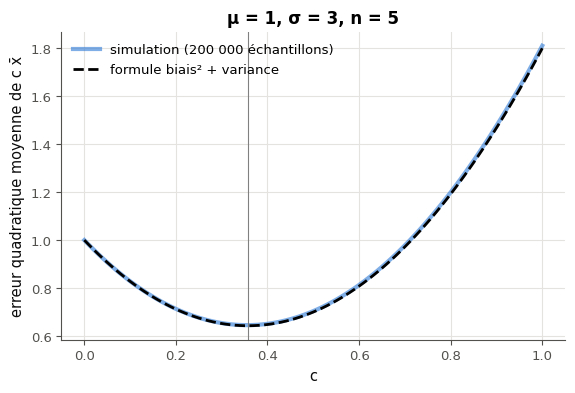

In [34]:
with checked("M09b.31 figure"):
    sim_fig_31 = np.asarray(simulated_mse(CS_31, 1.0, 3.0, 5), dtype=float)
    fig, ax = plt.subplots(figsize=(6.5, 4))
    ax.plot(CS_31, sim_fig_31, lw=3, alpha=0.6, label="simulation (200 000 échantillons)")
    ax.plot(CS_31, [formula_mse(c, 1.0, 3.0, 5) for c in CS_31], "k--", label="formule biais² + variance")
    ax.axvline(1.0 / (1.0 + 9.0 / 5), color="gray", lw=0.8)
    ax.set(xlabel="c", ylabel="erreur quadratique moyenne de c x̄", title="μ = 1, σ = 3, n = 5")
    ax.legend()
    plt.show()

💡 $E(c)$ est un polynôme du second degré en $c$ : $E'(c) = 2(c - 1)\mu^2 + 2c\frac{\sigma^2}{n} = 0$ donne $c^* = \frac{\mu^2}{\mu^2 + \sigma^2/n} = \frac{1}{2{,}8} \approx 0{,}3571$, et $E(c^*) = c^*\frac{\sigma^2}{n} \approx 0{,}643$, contre $E(1) = 1{,}8$ : 2,8 fois moins. Le rétrécissement paie quand la variance $\sigma^2/n$ de $\bar{x}$ est grande devant le carré du signal $\mu^2$ : on accepte un biais pour couper la variance. C'est ce que fait ridge sur les poids. Mais $c^*$ dépend de $\mu$, inconnu : en pratique on règle la force du rétrécissement par validation (comme le $\lambda$ de ridge, workbookIA 9).

### Ex M09b.32 — Le conditionnement de XᵀX avec des puissances non standardisées 🔬 ★★ ⏱️ 20 min
**Objectif :** mesurer le conditionnement de $\mathbf{X}^\top\mathbf{X}$ pour des features polynomiales, avec et sans mise à l'échelle de l'abscisse, et voir ce qu'il fait aux poids.  
**Prérequis :** fiche §4 ; Ex M09b.26 · **Parcours :** C

Le **conditionnement** d'une matrice carrée, `np.linalg.cond(A)`, dit à peu près par combien une petite erreur relative sur les données peut être multipliée dans la solution de $\mathbf{A}\mathbf{x} = \mathbf{b}$ (M12d en donnera la définition). Un `float64` a environ 16 chiffres significatifs : un conditionnement de $10^{16}$ peut tous les perdre. La cellule fournie définit 50 abscisses `x_32` entre 0 et 20, et les mêmes ramenées à $[-1, 1]$, `t_32`. Écris :
- `powers(x, degree)` : la matrice des colonnes $1, x, x^2, \ldots, x^{d}$ (forme $(n, d + 1)$) ;
- `cond_xtx(x, degree)` : le conditionnement de $\mathbf{X}^\top\mathbf{X}$ pour $\mathbf{X}$ = `powers(x, degree)`.

La vérification calcule :
- a) l'ordre de grandeur du conditionnement pour `x_32` et le degré 5 : la vérification compare l'exposant, `round(math.log10(...))` ;
- b) le même pour `t_32` et le degré 5 ;
- c) le plus petit degré de 1 à 8 pour lequel le conditionnement dépasse $10^{15}$ avec `x_32` ;
- d) vrai ou faux : avec `t_32`, il reste sous $10^6$ pour tous les degrés de 1 à 8.

Une dernière cellule modifie les cibles de $10^{-8}$ et compare la variation des poids et celle des prédictions, pour le degré 6.

Dans ta copie : pourquoi les colonnes $x^4$ et $x^5$ sur $[0, 20]$ sont-elles presque proportionnelles (fiche §4) ? Pourquoi les poids bougent-ils beaucoup, et les prédictions presque pas ? Quand cela devient-il grave ?

In [35]:
x_32 = np.linspace(0, 20, 50)                  # 50 abscissas between 0 and 20
t_32 = (x_32 - 10) / 10                           # the same, scaled to [-1, 1]

In [36]:
def powers(x, degree):
    """The matrix whose columns are 1, x, x², ..., x**degree (shape (n, degree + 1))."""
    x = np.asarray(x, dtype=float)
    return np.column_stack([x ** k for k in range(degree + 1)])


def cond_xtx(x, degree):
    """The condition number of XᵀX for X = powers(x, degree)."""
    X = powers(x, degree)
    return float(np.linalg.cond(X.T @ X))


for d in range(1, 9):
    print(f"degree {d}: raw {cond_xtx(x_32, d):.1e} · scaled {cond_xtx(t_32, d):.1e}")

degree 1: raw 5.3e+02 · scaled 2.9e+00
degree 2: raw 2.9e+05 · scaled 1.3e+01
degree 3: raw 1.5e+08 · scaled 6.2e+01
degree 4: raw 8.6e+10 · scaled 3.3e+02
degree 5: raw 5.3e+13 · scaled 1.7e+03
degree 6: raw 3.6e+16 · scaled 9.0e+03
degree 7: raw 2.4e+19 · scaled 4.8e+04
degree 8: raw 4.6e+21 · scaled 2.7e+05


In [37]:
wbm.record("M09b.32a", 14,
           mistakes={"le conditionnement de XᵀX, pas celui de X (il en est à peu près le carré)": 7,
                     "powers(x, d) a d + 1 colonnes, de x⁰ à x^d : le degré 5 va jusqu'à x⁵": 11})
wbm.record("M09b.32b", 3, mistakes={"le conditionnement de XᵀX, pas celui de X": 2})
wbm.record("M09b.32c", 6, mistakes={"le premier degré où le conditionnement dépasse 1e15 = 10¹⁵": {5, 7}})
wbm.record("M09b.32d", True,
           mistakes={"avec t_32 (entre −1 et 1), les puissances restent du même ordre de grandeur : vérifie powers et "
                     "cond_xtx": False})

WBM_ANSWER {"hash": "144a368feb68d5c01811baa9462cda5933ba063a65705a657656f8419af35f70", "id": "M09b.32a", "kind": "int", "magnitude": 1, "mistakes": {"0aa1b33648fc445f401c497cc4ca66330825cbfb4b73d2b21b42e91ca21db05a": "le conditionnement de XᵀX, pas celui de X (il en est à peu près le carré)", "a8379790c40ab21fe25a56a0c54c53056402729a0a335f328d7de3d6ffed9a43": "powers(x, d) a d + 1 colonnes, de x⁰ à x^d : le degré 5 va jusqu'à x⁵"}, "sign": 1}
📝 Ex M09b.32a : réponse enregistrée (int).
WBM_ANSWER {"hash": "7f036832beb11dc02f2fb56425c99971d81a92b6cddba98997f3aa83f7631e1c", "id": "M09b.32b", "kind": "int", "magnitude": 0, "mistakes": {"b387001a01000c061342ec39b4331ac290d8efb36413def0c7dd15403073c09a": "le conditionnement de XᵀX, pas celui de X"}, "sign": 1}
📝 Ex M09b.32b : réponse enregistrée (int).
WBM_ANSWER {"hash": "5611b019851c0d96566efda4414ffc12b4545e4f3f8fec207182fc7a30fc1d1f", "id": "M09b.32c", "kind": "int", "magnitude": 0, "mistakes": {"a36825bae310ae31679d30316517b5a3f1b62b96

**Ce que cela fait aux poids** (une expérience fournie, avec NumPy).

In [38]:
rng_32 = np.random.default_rng(32)
V6 = np.column_stack([x_32 ** k for k in range(7)])            # degree 6, raw powers
T6 = np.column_stack([t_32 ** k for k in range(7)])            # degree 6, scaled abscissas
target = np.sin(x_32 / 4)
nudged = target + 1e-8 * rng_32.normal(size=x_32.size)         # a change of 1e-8 in the data
for name, D in (("raw", V6), ("scaled", T6)):
    w0 = np.linalg.solve(D.T @ D, D.T @ target)
    w1 = np.linalg.solve(D.T @ D, D.T @ nudged)
    print(f"{name:6s} · largest relative change of a weight: {np.max(np.abs(w1 - w0) / np.abs(w0)):.1e}"
          f" · largest change of a prediction: {np.max(np.abs(D @ (w1 - w0))):.1e}")

raw    · largest relative change of a weight: 5.0e-06 · largest change of a prediction: 8.3e-09
scaled · largest relative change of a weight: 3.0e-08 · largest change of a prediction: 8.3e-09


💡 Sur $[0, 20]$, $x^5$ va jusqu'à $3{,}2 \times 10^6$ et la colonne de 1 reste à 1 ; surtout, les colonnes $x^4$ et $x^5$ pointent presque dans la même direction (fiche §4) : $\mathbf{X}^\top\mathbf{X}$ est presque singulière, avec un conditionnement de l'ordre de $10^{14}$ au degré 5 et de $10^{17}$ au degré 6. Ramener l'abscisse à $[-1, 1]$ le fait tomber à $10^3$ : c'est le rôle de la standardisation. Les poids bougent beaucoup, car beaucoup de combinaisons de colonnes presque dépendantes donnent presque les mêmes prédictions ; les prédictions, elles, restent stables. C'est grave quand on lit les poids (pour interpréter un modèle), quand on extrapole hors des données, ou quand le conditionnement atteint $10^{16}$ : `solve` peut alors rendre n'importe quoi. `lstsq` (sans former $\mathbf{X}^\top\mathbf{X}$) ne subit que la racine de ce conditionnement.

### Ex M09b.33 — Les lignes de niveau de la loss des moindres carrés en dimension 2, et son gradient 🎨 ★ ⏱️ 20 min
**Objectif :** tracer la loss des moindres carrés comme une fonction des deux poids, avec son minimum et les directions de descente, et voir l'effet du centrage sur sa forme.  
**Prérequis :** fiche §2 et §3 ; M05b (lignes de niveau) · **Parcours :** C

Pour une droite $\hat{y} = w_0 + w_1x$, la loss $L(w_0, w_1) = \lVert \mathbf{y} - \mathbf{X}\mathbf{w} \rVert^2$ est une fonction de **deux** variables : on peut tracer ses lignes de niveau dans le plan des poids. Écris `draw_loss(ax, X, y, w0_lim, w1_lim)`, qui dessine dans l'axe `ax`, sur le rectangle des poids $[w_0^{\min}, w_0^{\max}] \times [w_1^{\min}, w_1^{\max}]$ :
- au moins 8 lignes de niveau de $L$ (`ax.contour`, sur une grille fine faite par `np.meshgrid`) ; des niveaux en progression géométrique au-dessus du minimum, `L_min + np.geomspace(...)`, montrent mieux la forme ;
- le minimum, la solution des équations normales, par un seul point (`ax.plot(w0, w1, "*")`) ;
- les flèches de la **direction de descente** $-\nabla L(\mathbf{w}) = 2\mathbf{X}^\top(\mathbf{y} - \mathbf{X}\mathbf{w})$ sur une grille grossière d'au moins 16 points (`ax.quiver`).

La cellule de la figure s'en sert deux fois sur les cinq points fournis : avec l'abscisse $x$ brute, puis centrée ($x - \bar{x}$). Une cellule de vérification essaie ta fonction sur un autre dataset.

Dans ta copie : pourquoi les lignes de niveau sont-elles des ellipses (pense au degré de $L$) ? Pourquoi sont-elles si allongées et penchées avec $x$ brut, et alignées sur les axes avec $x$ centré (calcule $\mathbf{X}^\top\mathbf{X}$ dans les deux cas) ? Les flèches pointent-elles vers le minimum ? Qu'en déduis-tu pour une descente de gradient sur des données non centrées ?

In [39]:
x_33 = np.array([1.0, 2.0, 3.0, 4.0, 5.0])
y_33 = np.array([1.5, 2.0, 3.5, 3.0, 5.0])
X_33 = np.column_stack([np.ones(5), x_33])               # w = (w0, w1): ordinate at the origin, slope
Xc_33 = np.column_stack([np.ones(5), x_33 - x_33.mean()])  # the same with a centered abscissa

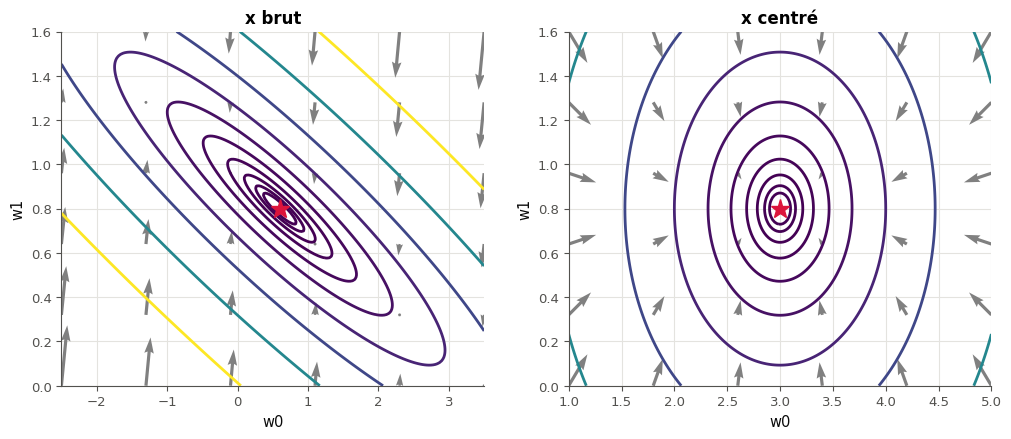

XᵀX raw: [[5.0, 15.0], [15.0, 55.0]] · XᵀX centered: [[5.0, 0.0], [0.0, 10.0]]


In [40]:
def draw_loss(ax, X, y, w0_lim, w1_lim):
    """In ax: level lines of L(w) = ‖y - Xw‖² over the rectangle w0_lim × w1_lim, the minimum (one point), and the
    descent directions -∇L(w) on a coarse grid (quiver)."""
    X, y = np.asarray(X, dtype=float), np.asarray(y, dtype=float)
    W0, W1 = np.meshgrid(np.linspace(*w0_lim, 200), np.linspace(*w1_lim, 200))
    residuals = y[None, None, :] - (W0[..., None] * X[:, 0] + W1[..., None] * X[:, 1])
    L = np.sum(residuals ** 2, axis=-1)
    w_star = np.linalg.solve(X.T @ X, X.T @ y)
    L_min = float(np.sum((y - X @ w_star) ** 2))
    ax.contour(W0, W1, L, levels=L_min + np.geomspace(0.05, 50, 10), cmap="viridis")
    ax.plot(w_star[0], w_star[1], "*", color="crimson", markersize=14)
    G0, G1 = np.meshgrid(np.linspace(*w0_lim, 6), np.linspace(*w1_lim, 6))
    descent = np.array([2 * X.T @ (y - X @ np.array([a, b])) for a, b in zip(G0.ravel(), G1.ravel())])
    ax.quiver(G0.ravel(), G1.ravel(), descent[:, 0], descent[:, 1], color="gray", angles="xy")


fig, axes = plt.subplots(1, 2, figsize=(12, 4.6))
draw_loss(axes[0], X_33, y_33, (-2.5, 3.5), (0.0, 1.6))
draw_loss(axes[1], Xc_33, y_33, (1.0, 5.0), (0.0, 1.6))
axes[0].set(title="x brut", xlabel="w0", ylabel="w1")
axes[1].set(title="x centré", xlabel="w0", ylabel="w1")
plt.show()
print("XᵀX raw:", (X_33.T @ X_33).tolist(), "· XᵀX centered:", (Xc_33.T @ Xc_33).tolist())

**Vérifications automatiques** (sur un autre dataset, dans des axes neufs).

In [41]:
with checked("M09b.33 vérifications"):
    import matplotlib.contour as mcontour
    import matplotlib.quiver as mquiver
    problems = []
    X_t = np.array([[1.0, -1.0], [1.0, 0.5], [1.0, 2.0], [1.0, 3.0]])    # another dataset
    y_t = np.array([0.0, 2.0, 1.0, 4.0])
    w_t = np.linalg.solve(X_t.T @ X_t, X_t.T @ y_t)
    fig_t, ax_t = plt.subplots()
    try:
        created = drawn(draw_loss, ax_t, X_t, y_t, (w_t[0] - 2, w_t[0] + 2), (w_t[1] - 1, w_t[1] + 1))
    finally:
        plt.close(fig_t)
    if created:
        problems.append("draw_loss ouvre sa propre figure : dessine dans l'axe reçu")
    else:
        contours = [c for c in ax_t.collections if isinstance(c, mcontour.ContourSet)]
        quivers = [c for c in ax_t.collections if isinstance(c, mquiver.Quiver)]
        points = [line for line in ax_t.get_lines() if len(line.get_xdata()) == 1]
        if not contours or len(contours[0].levels) < 8:
            problems.append("trace au moins 8 lignes de niveau de la loss (ax.contour)")
        if not any(np.allclose([line.get_xdata()[0], line.get_ydata()[0]], w_t, atol=1e-6) for line in points):
            problems.append("marque le minimum par un seul point (ax.plot(w0, w1, marker)), placé à la solution des "
                            "équations normales")
        if not quivers:
            problems.append("il manque les flèches de la descente (ax.quiver)")
        else:
            q = quivers[0]
            xy = np.asarray(q.get_offsets(), dtype=float)
            u, v = np.ravel(q.U), np.ravel(q.V)
            grads = np.array([-2 * X_t.T @ (y_t - X_t @ w) for w in xy])
            norms = np.hypot(grads[:, 0], grads[:, 1]) * np.hypot(u, v)
            keep = norms > 1e-12
            cosines = -(u * grads[:, 0] + v * grads[:, 1])[keep] / norms[keep]
            if xy.shape[0] < 16:
                problems.append("dessine au moins 16 flèches, sur une grille")
            elif cosines.size == 0 or np.min(cosines) < 0.999:
                problems.append("chaque flèche doit pointer dans la direction de descente, −∇L(w), en son point de "
                                "départ")
    if problems:
        print("❌ Ex M09b.33 : à revoir : " + " ; ".join(problems) + ".")
    else:
        print("✅ Ex M09b.33 : lignes de niveau, minimum et flèches de descente justes.")

✅ Ex M09b.33 : lignes de niveau, minimum et flèches de descente justes.


💡 $L$ est un polynôme du second degré en $(w_0, w_1)$, de partie quadratique $\mathbf{w}^\top\mathbf{X}^\top\mathbf{X}\mathbf{w}$ : ses lignes de niveau sont des ellipses centrées au minimum $(0{,}6 ;\ 0{,}8)$. Avec $x$ brut, $\mathbf{X}^\top\mathbf{X} = \begin{pmatrix} 5 & 15 \\ 15 & 55 \end{pmatrix}$ a un terme croisé : les ellipses sont penchées, et très allongées (le rapport de leurs axes est d'environ 8). Avec $x$ centré, $\mathbf{X}^\top\mathbf{X} = \begin{pmatrix} 5 & 0 \\ 0 & 10 \end{pmatrix}$ est diagonale : les axes des ellipses sont ceux du repère, et le minimum devient $(3 ;\ 0{,}8)$ (la même pente). Les flèches sont perpendiculaires aux lignes de niveau, pas dirigées vers le minimum : dans une vallée étroite, une descente de gradient zigzague d'un bord à l'autre et avance lentement (M19). Centrer, et standardiser, arrondit la vallée.

## Partie C · Erreurs classiques, savoir-faire et défi

Fiche §1 à §4. Trois erreurs à trouver, la vérification d'un gradient, puis une approximation polynomiale sous une erreur maximale.

### Ex M09b.34 — Chasse à l'erreur : XXᵀ au lieu de XᵀX, un gradient de mauvais signe, un R² sans centrer 🐛 ★ ⏱️ 15 min
**Objectif :** repérer dans du code les erreurs classiques des moindres carrés, puis calculer les bonnes valeurs.  
**Prérequis :** fiche §1, §2 et §3 · **Parcours :** C

Un collègue a écrit six lignes, chacune avec un commentaire qui dit ce qu'elle doit calculer. Trois lignes ne calculent pas ce que dit leur commentaire. **Sans exécuter de code**, trouve-les.

```python
X = np.array([[1.0, 2.0], [1.0, -1.0], [1.0, 0.0]])    # 3 examples: a column of ones, then one feature
y = np.array([3.0, 0.0, 2.0])
w = np.array([1.0, 0.5])
G = X @ X.T                                   # (A) the 2 × 2 matrix XᵀX of the normal equations: G[0, 1]
r = y - X @ w                                 # (B) the residuals of the predictions Xw: r[0]
g = 2 * X.T @ (y - X @ w)                     # (C) the gradient of ‖y − Xw‖² at w: g[1]
w_new = w + 0.1 * 2 * X.T @ r                 # (D) one gradient descent step on ‖y − Xw‖², with η = 0.1: w_new[1]
r2 = 1 - np.sum(r ** 2) / np.sum(y ** 2)      # (E) the R² of the predictions Xw
mse = np.mean(r ** 2)                         # (F) the MSE of the predictions Xw
```

Questions :
- a) les lettres des lignes fausses, dans l'ordre alphabétique (un texte) ;
- b) pour chacune des six lignes, de (A) à (F), la bonne valeur de ce que dit son commentaire (une liste de 6 nombres, 4 décimales).

Dans ta copie : pour chaque ligne fausse, quelle erreur a été faite, et comment la corriger ? La ligne (A) s'exécute sans erreur : quelle est la forme de son résultat, et pourquoi Python ne signale-t-il rien ? La ligne (D) ajoute au lieu de retrancher : pourquoi est-elle juste ?

In [42]:
answer_M09b_34a = "ACE"
X = np.array([[1.0, 2.0], [1.0, -1.0], [1.0, 0.0]])
y = np.array([3.0, 0.0, 2.0])
w = np.array([1.0, 0.5])
G = X.T @ X                                   # (A) XᵀX, of shape (2, 2): X @ X.T is the (3, 3) matrix of the examples
r = y - X @ w                                 # (B) correct
g = -2 * X.T @ (y - X @ w)                    # (C) the gradient has a minus sign
w_new = w + 0.1 * 2 * X.T @ r                 # (D) correct: w − η ∇L = w + 2η Xᵀr
r2 = 1 - np.sum(r ** 2) / np.sum((y - y.mean()) ** 2)   # (E) SST is around the mean of y
mse = np.mean(r ** 2)                         # (F) correct
answer_M09b_34b = [float(G[0, 1]), float(r[0]), float(g[1]), float(w_new[1]), float(r2), float(mse)]
print(answer_M09b_34a, np.round(answer_M09b_34b, 4))

ACE [ 1.      1.     -5.      1.      0.5179  0.75  ]


In [43]:
wbm.record("M09b.34a", "ACE",
           mistakes={"il manque une ligne fautive : écris la forme de chaque matrice": "CE",
                     "il manque une ligne fautive : dérive à nouveau ‖y − Xw‖² : d'où vient le signe ?": "AE",
                     "il manque une ligne fautive : écris la définition du R² de la fiche §1": "AC",
                     "une ligne de trop : une des lignes que tu cites est correcte ; refais le calcul de chacune sur un petit exemple": {"ABCE", "ACDE", "ACEF"},
                     "une des lignes que tu cites est correcte, et il manque une ligne fautive : écris la forme de chaque matrice": {"BCE", "CDE", "CEF"},
                     "une des lignes que tu cites est correcte, et il manque une ligne fautive : dérive à nouveau ‖y − Xw‖² : d'où vient le signe ?": {"ABE", "ADE", "AEF"},
                     "une des lignes que tu cites est correcte, et il manque une ligne fautive : écris la définition du R² de la fiche §1": {"ABC", "ACD", "ACF"},
                     "plusieurs lignes fautives manquent : reprends chaque ligne avec un petit exemple": {"A", "C", "E"},
                     "il manque des lignes fautives, et des lignes que tu cites sont correctes : reprends chaque ligne avec un petit exemple": {"B", "D", "F", "AB", "AD", "AF", "BC", "BD", "BE", "BF", "CD", "CF", "DE", "DF", "EF", "ABD", "ABF", "ADF", "BCD", "BCF", "BDE", "BDF", "BEF", "CDF", "DEF", "ABCD", "ABCF", "ABDE", "ABDF", "ABEF", "ACDF", "ADEF", "BCDE", "BCDF", "BCEF", "BDEF", "CDEF", "ABCDF", "ABDEF", "BCDEF"},
                     "plusieurs lignes que tu cites sont correctes : vérifie chacune avec un petit exemple": {"ABCDE", "ABCEF", "ACDEF", "ABCDEF"}})
VALUES_34 = [1.0, 1.0, -5.0, 1.0, 1 - 2.25 / (42 / 9), 0.75]
wbm.record("M09b.34b", VALUES_34, decimals=4,
           mistakes={"(A) : XᵀX a une ligne et une colonne par feature ; X @ X.T en a une par exemple":
                         [-1.0] + VALUES_34[1:],
                     "(C) : le gradient de ‖y − Xw‖² est −2Xᵀ(y − Xw)": VALUES_34[:2] + [5.0] + VALUES_34[3:],
                     "(E) : le R² compare la somme des carrés des résidus à celle des écarts à la moyenne de y":
                         VALUES_34[:4] + [1 - 2.25 / 13] + VALUES_34[5:]})

WBM_ANSWER {"hash": "c67bede1cffaaef849f3c835adf2d45b7d432ba1aa6dc44720398013d7133f0a", "id": "M09b.34a", "kind": "str", "mistakes": {"0539868483d48dca08e40690c9303f766d5dcccd15b7bb652c60785b4a2fe502": "il manque des lignes fautives, et des lignes que tu cites sont correctes : reprends chaque ligne avec un petit exemple", "0a514395916dc0edc68679a8815e969f459744bf841706b0bec03013bab46fc2": "il manque des lignes fautives, et des lignes que tu cites sont correctes : reprends chaque ligne avec un petit exemple", "0e70677fe6cee07fa24344fa6f8277f2eac680e0ac5b26fbd8250de0de4375d2": "il manque des lignes fautives, et des lignes que tu cites sont correctes : reprends chaque ligne avec un petit exemple", "0f1e7cc271315f2a3a5fe2353d45b5fd026302c71e79afb74f2906691581a697": "il manque des lignes fautives, et des lignes que tu cites sont correctes : reprends chaque ligne avec un petit exemple", "0f8ec1a404fe4d1a895311c77fc2ae2f8aa6c98ad28265267fd87d1e97570705": "il manque des lignes fautives, et des

💡 (A) `X @ X.T` est de forme $(3, 3)$ : la matrice des produits scalaires des **exemples**, dont l'élément $(1, 2)$ existe, d'où l'absence d'erreur ; $\mathbf{X}^\top\mathbf{X}$ s'écrit `X.T @ X`, et son élément $(1, 2)$ vaut $\sum_i x_i = 1$. (B) est juste : $\hat{\mathbf{y}} = (2 ;\ 0{,}5 ;\ 1)$, $r_1 = 1$. (C) Il manque le signe moins : $\nabla L = -2\mathbf{X}^\top\mathbf{r} = -2(1{,}5 ;\ 2{,}5) = (-3, -5)$. (D) est juste : $\mathbf{w} - \eta\nabla L = \mathbf{w} + 2\eta\mathbf{X}^\top\mathbf{r}$, et $0{,}5 + 0{,}2 \times 2{,}5 = 1$. (E) $\sum y_i^2 = 13$ compare à la prédiction 0 ; avec $\bar{y} = \frac{5}{3}$, $\mathrm{SCT} = \frac{42}{9}$ et $R^2 = 1 - \frac{2{,}25}{42/9} \approx 0{,}5179$, au lieu de $0{,}8269$. (F) est juste : $\frac{2{,}25}{3} = 0{,}75$.

### Ex M09b.35 — Vérifier un gradient matriciel avec SymPy et par différences finies 🛠️ ★ ⏱️ 15 min
**Objectif :** vérifier une formule de gradient de deux façons : numériquement, par des différences finies centrées, et exactement, avec SymPy.  
**Prérequis :** fiche §2 ; M05a (différences finies) ; Ex M09b.13 · **Parcours :** C

Une formule de gradient fausse ne fait pas planter le code : la descente converge mal, ou vers le mauvais point. Avant de s'en servir, on la vérifie : c'est la **vérification du gradient** (*gradient checking*). Écris :
- `numerical_gradient(f, w, h=1e-6)` : le gradient de `f` en `w` par différences finies **centrées**, $\frac{f(\mathbf{w} + h\mathbf{e}_k) - f(\mathbf{w} - h\mathbf{e}_k)}{2h}$ pour chaque coordonnée $k$ (un tableau NumPy) ;
- `gradient_error(f, grad, w)` : le plus grand écart, en valeur absolue, entre `numerical_gradient(f, w)` et `grad(w)`, divisé par $\max(1, \text{la plus grande valeur absolue du gradient numérique})$ ;
- `symbolic_check(p)` : avec SymPy, un vecteur $\mathbf{w}$ de $p$ symboles et une matrice $\mathbf{A}$ de $p^2$ symboles (`sympy.symbols`, `sympy.Matrix`), le gradient de $\mathbf{w}^\top\mathbf{A}\mathbf{w}$ (`sympy.diff` sur chaque $w_k$) ; rends `True` si sa différence avec $(\mathbf{A} + \mathbf{A}^\top)\mathbf{w}$, développée (`sympy.expand`), est nulle, en `bool` de Python.

La vérification essaie `numerical_gradient` sur une fonction de gradient connu, puis `gradient_error` sur $(\mathbf{A} + \mathbf{A}^\top)\mathbf{w}$ (juste), sur $2\mathbf{A}\mathbf{w}$ (faux, $\mathbf{A}$ n'étant pas symétrique) et sur le gradient des moindres carrés ; enfin `symbolic_check(3)`.

Dans ta copie : pourquoi des différences **centrées** plutôt que $\frac{f(\mathbf{w} + h\mathbf{e}_k) - f(\mathbf{w})}{h}$ (M05a) ? Pourquoi pas $h = 10^{-12}$ ? Pourquoi `gradient_error` divise-t-il par la taille du gradient ? Combien d'évaluations de `f` coûte un gradient numérique, et pourquoi ne s'en sert-on pas pour entraîner un réseau ?

In [44]:
def numerical_gradient(f, w, h=1e-6):
    """The gradient of f at w by centered finite differences, one coordinate at a time."""
    w = np.asarray(w, dtype=float)
    grad = np.zeros_like(w)
    for k in range(w.size):
        step = np.zeros_like(w)
        step[k] = h
        grad[k] = (f(w + step) - f(w - step)) / (2 * h)
    return grad


def gradient_error(f, grad, w):
    """max |numerical gradient − grad(w)|, divided by max(1, max |numerical gradient|)."""
    approx = numerical_gradient(f, w)
    return float(np.max(np.abs(approx - np.asarray(grad(w), dtype=float))) / max(1.0, np.max(np.abs(approx))))


def symbolic_check(p):
    """True if the SymPy gradient of wᵀAw (w: p symbols, A: p² symbols) equals (A + Aᵀ)w."""
    w = sympy.Matrix(sympy.symbols(f"w1:{p + 1}"))
    A = sympy.Matrix(p, p, sympy.symbols(f"a1:{p * p + 1}"))
    f = (w.T * A * w)[0, 0]
    gradient = sympy.Matrix([sympy.diff(f, wk) for wk in w])
    return bool(sympy.expand(gradient - (A + A.T) * w) == sympy.zeros(p, 1))


print(symbolic_check(2), symbolic_check(3))

True True


In [45]:
with checked("M09b.35 vérifications"):
    problems = []
    w_t = np.array([0.3, -1.2, 2.0])
    approx_t = np.asarray(numerical_gradient(lambda v: float(np.sum(np.sin(v))), w_t), dtype=float)
    if approx_t.shape != w_t.shape or not np.allclose(approx_t, np.cos(w_t), rtol=0, atol=1e-8):
        problems.append("numerical_gradient ne donne pas le gradient de sum(sin(w)), qui vaut cos(w) : différence "
                        "centrée (f(w + h e_k) − f(w − h e_k)) / (2h), une coordonnée à la fois")
    else:
        rng_t = np.random.default_rng(35)
        A_t, X_t, y_t = rng_t.normal(size=(3, 3)), rng_t.normal(size=(6, 3)), rng_t.normal(size=6)
        quad_t = lambda v: float(v @ A_t @ v)                                    # noqa: E731
        good_t = gradient_error(quad_t, lambda v: (A_t + A_t.T) @ v, w_t)
        bad_t = gradient_error(quad_t, lambda v: 2 * A_t @ v, w_t)
        ls_t = gradient_error(lambda v: float(np.sum((y_t - X_t @ v) ** 2)), lambda v: -2 * X_t.T @ (y_t - X_t @ v), w_t)
        print(f"(A + Aᵀ)w : {good_t:.1e} · 2Aw : {bad_t:.1e} · −2Xᵀ(y − Xw) : {ls_t:.1e}")
        if not (good_t < 1e-8 and ls_t < 1e-8):
            problems.append("gradient_error doit être minuscule pour un gradient juste : compare numerical_gradient(f, "
                            "w) et grad(w), puis divise le plus grand écart par max(1, la plus grande valeur absolue)")
        elif not bad_t > 1e-2:
            problems.append("gradient_error doit être grand pour 2Aw, faux quand A n'est pas symétrique")
    try:
        same = symbolic_check(3)
    except NotImplementedError:
        raise
    if same is not True:
        problems.append("symbolic_check(3) doit rendre True : le gradient de SymPy et (A + Aᵀ)w, simplifiés, doivent "
                        "coïncider (renvoie un bool de Python)")
    if problems:
        print("❌ Ex M09b.35 : à revoir : " + " ; ".join(problems) + ".")
    else:
        print("✅ Ex M09b.35 : le gradient numérique, la mesure d'erreur et la vérification symbolique sont justes.")

(A + Aᵀ)w : 1.4e-10 · 2Aw : 1.6e+00 · −2Xᵀ(y − Xw) : 7.9e-11
✅ Ex M09b.35 : le gradient numérique, la mesure d'erreur et la vérification symbolique sont justes.


💡 La différence centrée a une erreur d'ordre $h^2$ (les termes en $h$ du développement de Taylor se compensent, M05a), contre $h$ pour la différence avant : avec $h = 10^{-6}$, environ $10^{-12}$ contre $10^{-6}$. Un $h$ trop petit fait perdre des chiffres : $f(\mathbf{w} + h\mathbf{e}_k)$ et $f(\mathbf{w} - h\mathbf{e}_k)$ sont presque égaux, et leur différence est dominée par les arrondis (environ $10^{-16}/h$). Diviser par la taille du gradient rend la mesure indépendante de l'échelle de $f$. Un gradient numérique coûte $2p$ évaluations de $f$ : pour un réseau à un million de poids, deux millions de passes avant par pas, alors que la rétropropagation (M18) donne le gradient exact pour environ le coût de deux passes. On ne s'en sert que pour vérifier.

### Ex M09b.36 — Défi : approcher une fonction par un polynôme de degré au plus 5, avec une erreur maximale sous 1e−3 🏆 ★★★ ⏱️ 25 min
**Objectif :** construire, avec tes moindres carrés, un polynôme de degré au plus 5 dont l'erreur maximale sur tout un intervalle passe sous $10^{-3}$.  
**Prérequis :** fiche §3 et §4 ; Ex M09b.26 et M09b.32 · **Parcours :** C

La fonction $f(x) = \frac{20}{20 + x}$ décroît de 1 à $\frac{1}{3}$ sur $[0, 40]$. **L'objectif** : un polynôme $p$ de degré au plus 5 tel que $\max_{x \in [0, 40]} |p(x) - f(x)| < 10^{-3}$, l'erreur étant mesurée sur la grille `GRID_36` de 4 001 points. Le polynôme s'écrit dans la variable $t = \frac{x - 20}{20}$, qui va de $-1$ à $1$ (M09b.32 dit pourquoi) : $p = c_0 + c_1t + \cdots + c_5t^5$.

Écris `fit_36()`, qui rend les coefficients $(c_0, \ldots, c_5)$ (au plus 6 nombres), calculés avec **ta** fonction `mymath.linreg.solve_least_squares` (sans `np.polyfit` ni `lstsq`) à partir de points $(x_i, f(x_i))$ que tu choisis. La cellule fournie définit `target_36`, `GRID_36` et `evaluate_36(coefficients, x)`, qui évalue ton polynôme.

Commence par le plus simple : les moindres carrés sur les 4 001 points de la grille. Mesure l'erreur maximale et regarde **où** elle est atteinte. La vérification affiche ton erreur maximale et l'endroit où elle est atteinte.

Dans ta copie : quelle erreur donnait ta première version, et où était-elle la plus grande ? Qu'as-tu changé ? Pourquoi les moindres carrés ne minimisent-ils pas l'erreur maximale ? Un degré 4 pourrait-il suffire (essaie) ?

In [46]:
def target_36(x):
    """The function to approximate on [0, 40]."""
    return 20 / (20 + np.asarray(x, dtype=float))


GRID_36 = np.linspace(0, 40, 4001)                # where the maximal error is measured


def evaluate_36(coefficients, x):
    """The polynomial sum_k coefficients[k] * t**k, with t = (x - 20) / 20 (t goes from -1 to 1)."""
    t = (np.asarray(x, dtype=float) - 20) / 20
    return sum(c * t ** k for k, c in enumerate(coefficients))

In [47]:
def fit_36():
    """At most 6 coefficients c_0, ..., c_5 of a polynomial in t = (x - 20) / 20 that approximates target_36 on
    [0, 40] with a maximal error below 1e-3, computed with mymath.linreg.solve_least_squares."""
    k = np.arange(30)
    t = np.cos((2 * k + 1) * np.pi / 60)              # 30 Chebyshev points: denser near the ends of [-1, 1]
    T = np.column_stack([t ** j for j in range(6)])
    return mymath.linreg.solve_least_squares(T, target_36(20 + 20 * t))


mymath = wbm.load_mymath("ref")
t_uniform = (GRID_36 - 20) / 20
first = mymath.linreg.solve_least_squares(np.column_stack([t_uniform ** j for j in range(6)]), target_36(GRID_36))
print("first try, least squares on the 4001 points of the grid:",
      f"{np.max(np.abs(evaluate_36(first, GRID_36) - target_36(GRID_36))):.2e}")
print("Chebyshev points:", f"{np.max(np.abs(evaluate_36(fit_36(), GRID_36) - target_36(GRID_36))):.2e}")

first try, least squares on the 4001 points of the grid: 1.27e-03
Chebyshev points: 5.84e-04


In [48]:
wbm.record("M09b.36", True,
           mistakes={"l'erreur maximale n'est pas sous 1e-3 : la cellule du défi dit où elle est atteinte": False})

WBM_ANSWER {"hash": "38c493c2a6b0121b65f5d35a0ed6cdbc29a958d186e199e46fa0611350f854ea", "id": "M09b.36", "kind": "bool", "mistakes": {"35943a098a2effeac7479cd8a334e6f98ae77af96baa720231ec4c2ff3d702e9": "l'erreur maximale n'est pas sous 1e-3 : la cellule du défi dit où elle est atteinte"}}
📝 Ex M09b.36 : réponse enregistrée (bool).


In [49]:
with checked("M09b.36 défi"):
    ok_36 = False
    coefficients_36 = fit_36()
    coefficients_36 = np.asarray(coefficients_36, dtype=float).ravel()
    if coefficients_36.size == 0 or coefficients_36.size > 6:
        print(f"❌ Ex M09b.36 : {coefficients_36.size} coefficients : un polynôme de degré au plus 5 en a au plus 6.")
    elif not np.all(np.isfinite(coefficients_36)):
        print("❌ Ex M09b.36 : des coefficients non finis.")
    else:
        error_36 = float(np.max(np.abs(evaluate_36(coefficients_36, GRID_36) - target_36(GRID_36))))
        worst_36 = float(GRID_36[np.argmax(np.abs(evaluate_36(coefficients_36, GRID_36) - target_36(GRID_36)))])
        print(f"erreur maximale : {error_36:.2e}, atteinte en x = {worst_36:g}")
        if error_36 < 1e-3:
            ok_36 = True
            print("✅ Ex M09b.36 : défi réussi : l'erreur maximale est sous 1e-3.")
        else:
            print("❌ Ex M09b.36 : l'erreur maximale dépasse 1e-3. Regarde où elle est atteinte : les moindres carrés "
                  "minimisent une somme de carrés, pas l'erreur maximale.")

erreur maximale : 5.84e-04, atteinte en x = 0
✅ Ex M09b.36 : défi réussi : l'erreur maximale est sous 1e-3.


💡 Les moindres carrés sur une grille uniforme donnent une erreur maximale d'environ $1{,}3 \times 10^{-3}$, atteinte en $x = 0$ : ils minimisent la **somme** des carrés, où les deux bords comptent peu (peu de points y sont « coincés » d'un seul côté), et l'erreur s'y concentre. Il faut donner plus de poids aux bords : des points plus serrés près de $-1$ et $1$, comme les **points de Tchebychev** $t_k = \cos\frac{(2k + 1)\pi}{2m}$ (environ $5{,}8 \times 10^{-4}$), des poids plus grands près des bords (multiplier les lignes de $\mathbf{X}$ et de $\mathbf{y}$ par $\sqrt{\text{poids}}$), ou des passes successives qui augmentent le poids des points mal approchés. Un degré 4 ne suffit pas : même le meilleur polynôme de degré 4 a une erreur maximale d'environ $1{,}7 \times 10^{-3}$. La meilleure erreur maximale possible en degré 5 est d'environ $4{,}6 \times 10^{-4}$ (le polynôme « minimax », que des passes successives approchent).

## ✅ Bilan

**Auto-évaluation** (note-toi de 0 à 3 dans `mon_travail/suivi/auto_evaluation.md`) :
1. Sais-tu calculer une MSE, une MAE, une loss de Huber et un $R^2$, et dire ce que mesure chacun ?
2. Sais-tu calculer les gradients de $\mathbf{a}^\top\mathbf{w}$, de $\mathbf{w}^\top\mathbf{A}\mathbf{w}$ et de $\lVert \mathbf{y} - \mathbf{X}\mathbf{w} \rVert^2$, et en tirer les équations normales ?
3. Sais-tu expliquer les moindres carrés comme une projection, et les propriétés de la matrice chapeau ?
4. Sais-tu résoudre un problème ridge, dire pourquoi il a toujours une solution, et le relier à un prior gaussien ?
5. Sais-tu relier les moindres carrés au bruit gaussien, et décomposer une erreur en biais², variance et bruit ?

**La suite** : le chapitre 9 de workbookIA (overfitting, underfitting et régularisation, avec ses propres implémentations), puis M10, la séparabilité linéaire et la convexité.